# Questão 1 — Comparação de documentos parecidos: demonstração

Python 3.14, `pymupdf`, `numpy`, `matplotlib`, `sentence-transformers` (versões em `requirements.txt`). Dados sintéticos, seeds fixas; as paráfrases da faixa semântica estão em `parafrases_q1.json`. Rodar com *Restart & Run All* (a primeira execução baixa o modelo de embedding, ~1 GB).

## 0. Configuração e limiares

*Afirmação:* Todos os cortes num só lugar; nenhum é ajustado no conjunto de teste.

In [1]:
import json
import math
import random
import re
import sys
import time
import unicodedata

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pymupdf

from q1 import *   # código da solução (§0–§11); este caderno só executa as demonstrações

import sentence_transformers

print(f"Python {sys.version.split()[0]} | pymupdf {pymupdf.__version__} | numpy {np.__version__} | matplotlib {matplotlib.__version__} "
      f"| sentence-transformers {sentence_transformers.__version__} ({MODELO_EMBEDDING.split('/')[-1]})")
print(f"Pipeline {VERSAO_PIPELINE} | {LIMIARES}")

Python 3.14.6 | pymupdf 1.28.2 | numpy 2.5.4 | matplotlib 3.11.2 | sentence-transformers 6.1.0 (paraphrase-multilingual-mpnet-base-v2)
Pipeline q1-v3 | Limiares(padrao_min_casos=3, historico_min_casos=20, derivacao_sem_historico=0.9, derivacao=0.6, documento_inteiro=0.5, diferente=0.2, min_shingles=10, lacuna=25, min_regiao=15, regra_texto_minimo=True, cosseno_par=0.875, cosseno_par_minimo=0.725, cobertura_versao=0.65, cobertura_diferente=0.55, reescrita_mesma_peca=0.6)


## 1. Representação do documento
### 1.1 Normalização de lista branca

*Afirmação:* Só diferenças sem efeito jurídico somem na normalização; vírgula, número, negação e folhas continuam diferenças.

In [2]:
exemplos_cosmeticos = {
    "NFD × NFC": ("A petição foi protocolada.", unicodedata.normalize("NFD", "A petição foi protocolada.")),
    "hifenização de quebra de linha": ("serviços de manutenção predial", "serviços de manu-\ntenção predial"),
    "linha 'Página N de M'": ("Primeiro parágrafo.\nSegundo parágrafo.", "Primeiro parágrafo.\nPágina 2 de 9\nSegundo parágrafo."),
    "palavra hifenizada em volta do rodapé": ("a consumidora pagou", "a cons-\nPágina 1 de 9\numidora pagou"),
    "aspas e travessão tipográficos": ('o "contrato" - assinado', "o “contrato” — assinado"),
    "caixa e espaços": ("Requer a citação da ré.", "REQUER  a   citação da ré."),
    "parágrafo quebrado em dois": ("A autora contratou a ré e pagou.", "A autora contratou a ré\ne pagou."),
}
for nome, (a, b) in exemplos_cosmeticos.items():
    assert a != b and chave_cosmetica(a) == chave_cosmetica(b), nome
    print(f"cosmético ✅  {nome}")

exemplos_materiais = {
    "vírgula removida": ("Não, houve pagamento.", "Não houve pagamento."),
    "espaço dentro de número": ("R$ 12.500,00", "R$ 1 2.500,00"),
    "palavras unidas": ("a ré pagou", "aré pagou"),
    "um centavo": ("R$ 12.500,00", "R$ 12.500,01"),
    "negação": ("houve quitação", "não houve quitação"),
    "intervalo quebrado na linha": ("pagou as parcelas 10-\n20 do contrato", "pagou as parcelas 1020 do contrato"),
    "referência a folhas em linha própria": ("juntado às\nfls. 120\ne seguintes", "juntado às\nfls. 245\ne seguintes"),
}
for nome, (a, b) in exemplos_materiais.items():
    assert chave_cosmetica(a) != chave_cosmetica(b), nome
    print(f"material  ✅  {nome}")

cosmético ✅  NFD × NFC
cosmético ✅  hifenização de quebra de linha
cosmético ✅  linha 'Página N de M'
cosmético ✅  palavra hifenizada em volta do rodapé
cosmético ✅  aspas e travessão tipográficos
cosmético ✅  caixa e espaços
cosmético ✅  parágrafo quebrado em dois
material  ✅  vírgula removida
material  ✅  espaço dentro de número
material  ✅  palavras unidas
material  ✅  um centavo
material  ✅  negação
material  ✅  intervalo quebrado na linha
material  ✅  referência a folhas em linha própria


### 1.2 Campos críticos

*Afirmação:* Valores, datas, CPF, CNPJ e processo são extraídos para destacar alterações; não decidem a classe.

In [3]:
exemplo = "Processo 0001234-56.2024.8.26.0100. CPF 123.456.789-09, valor R$ 12.500,00, vencido em 15 de março de 2024."
print(json.dumps({k: list(v) for k, v in extrair_campos(exemplo).items()}, ensure_ascii=False))
print(alteracoes_de_campos(extrair_campos(exemplo), extrair_campos(exemplo.replace("12.500,00", "18.900,00"))))

{"valor": ["r$ 12.500,00"], "data": ["15 de março de 2024"], "cpf": ["123.456.789-09"], "cnpj": [], "processo": ["0001234-56.2024.8.26.0100"]}
{'valor': {'antes': ['r$ 12.500,00'], 'depois': ['r$ 18.900,00']}}


### 1.3 Documento: fluxo de palavras, parágrafos com página, citações, partes

*Afirmação:* O documento vira um fluxo de palavras com parágrafo e página, marcas de citação, partes e tipo de peça.

In [4]:
demo = representar("demo", ["Primeiro parágrafo com manu-\ntenção predial.\nPágina 1 de 2", 'Segundo parágrafo cita: "a ré não pagou nenhuma das parcelas vencidas do contrato".'])
for p in demo.paragrafos:
    print(f"§{p.indice} pág.{p.pagina} [{p.inicio}:{p.fim}] {p.texto!r} → palavras {p.p0}–{p.p1 - 1}")
print("palavras citadas:", [w for w, c in zip(demo.palavras, demo.citada) if c])
assert len(demo.paragrafos) == 2 and demo.paragrafos[0].texto == "Primeiro parágrafo com manutenção predial."
assert sum(demo.citada) == 10
for abertura, tipo in [("vem propor a presente AÇÃO DE COBRANÇA em face de", "inicial"), ("vem apresentar CONTESTAÇÃO, pelos fatos", "contestação"),
                       ("vem apresentar MEMORIAIS", "memoriais"), ("Requer a citação para apresentar contestação no prazo legal.", "")]:
    assert extrair_tipo([abertura]) == tipo, abertura

§0 pág.1 [0:44] 'Primeiro parágrafo com manutenção predial.' → palavras 0–4
§1 pág.2 [59:142] 'Segundo parágrafo cita: "a ré não pagou nenhuma das parcelas vencidas do contrato".' → palavras 5–17
palavras citadas: ['a', 'ré', 'não', 'pagou', 'nenhuma', 'das', 'parcelas', 'vencidas', 'do', 'contrato']


## 2. Texto de modelo aprendido no histórico do cliente

*Afirmação:* O que se repete em vários casos do mesmo cliente é modelo e não conta como texto em comum; o que só aparece no caso atual é conteúdo do caso. Não há lista fixa de textos.

In [5]:
print("O mesmo modelo em três petições do escritório:\n")
for k in range(3):
    print(f"  {instanciar(MODELOS_ESCRITORIO[0], random.Random(40 + k))}")
print("\nExemplo de petição gerada (seed 7):\n")
print(gerar_peca(random.Random(7), "serviços", n_fatos=(2, 2)).texto)

O mesmo modelo em três petições do escritório:

  Pelo exposto, requer o regular prosseguimento do feito, com observância das formalidades legais, com a intimação das partes para todos os atos processuais.
  Ante o exposto, requer o prosseguimento regular da ação, com observância das formalidades legais, com a intimação das partes para todos os atos processuais.
  Ante o exposto, postula o prosseguimento regular da ação, e a intimação das partes para todos atos processuais.

Exemplo de petição gerada (seed 7):

EXCELENTÍSSIMO SENHOR DOUTOR JUIZ DE DIREITO DA 38ª VARA CÍVEL DA COMARCA DE CAMPINAS
João Pereira Carvalho, CPF nº 099.603.082-46, com endereço em Campinas, vem, por sua advogada, propor a presente AÇÃO DE COBRANÇA em face de Alfa Serviços Prediais Ltda., CNPJ nº 19.093.786/5797-54, pelos fatos e fundamentos a seguir expostos.
DOS FATOS
A prestadora, na Rua Sete de Setembro, nº 85, registrou o termo de aceite parcial mediante protocolo nº 6138. A equipe técnica da autora, no di

In [6]:
print(f"Histórico do cliente: {INDICE.n_casos} casos, {INDICE.distintas:,} sequências distintas, {len(INDICE.casos_com):,} em ≥3 casos "
      f"(snapshot v{INDICE.versao})")
rng_exemplo = random.Random(1)
for rotulo, trecho in [("modelo do escritório (variante nova)", instanciar(MODELOS_ESCRITORIO[0], rng_exemplo)),
                       ("modelo que o cliente nunca usou", instanciar(MODELOS_NOVOS[0], rng_exemplo)),
                       ("fato do caso", "A autora realizou a troca das bombas hidráulicas na unidade comercial 17 em 3 de março de 2024.")]:
    sh = shingles_de(palavras(normalizar(trecho)))
    print(f"{sum(INDICE.eh_padrao(s) for s in sh):>3}/{len(sh):<3} sequências reconhecidas como modelo | {rotulo}: {trecho[:70]}…")

# Snapshot versionado: conta casos (não documentos), desconta o caso atual, exclui um caso e grava a versão na decisão.
frase = instanciar(MODELOS_NOVOS[1], random.Random(2), deriva=0)
s0 = shingles_de(palavras(normalizar(frase)))[0]
teste_indice = IndiceDoCliente({"c1": [frase], "c2": [frase, frase], "atual": [frase]})
assert teste_indice.casos_com[s0] == 3                                    # 4 documentos, 3 casos
assert teste_indice.eh_padrao(s0) and not teste_indice.eh_padrao(s0, caso_atual="atual")   # 2 outros casos + o atual: não é modelo
teste_indice.adicionar_caso("c3", [frase])
assert not teste_indice.eh_padrao(s0, caso_atual="atual")                 # ainda não publicado
v1_indice = teste_indice.versao
teste_indice.publicar()
assert teste_indice.eh_padrao(s0, caso_atual="atual")                     # 3 outros casos: é modelo
teste_indice.remover_caso("atual")
teste_indice.publicar()
assert teste_indice.casos_com[s0] == 3 and teste_indice.eh_padrao(s0)    # exatamente 3 casos: modelo
teste_indice.remover_caso("c3")
teste_indice.publicar()
assert not teste_indice.eh_padrao(s0)                                     # exclusão de um caso: 2 casos, deixa de ser modelo
indice_v = IndiceDoCliente(gerar_historico(seed=0, n_casos=20))
peca_v = gerar_peca(random.Random(3), "consumo")
par_v = [indexar(representar(x, t), indice_v) for x, t in (("x", peca_v.texto), ("y", peca_v.texto.replace(peca_v.campos["valor"], "R$ 1,00")))]
d_v1 = decidir(comparar(*par_v))
indice_v.publicar()
d_v2 = decidir(comparar(*(indexar(d, indice_v) for d in par_v)))
print(f"mesmo par: snapshot v{d_v1.indice_versao} → {d_v1.classe}; snapshot v{d_v2.indice_versao} → {d_v2.classe}; pipeline {d_v2.versao_pipeline}")
assert (d_v1.indice_versao, d_v2.indice_versao) == (v1_indice, v1_indice + 1) and d_v1.classe == d_v2.classe

Histórico do cliente: 80 casos, 37,423 sequências distintas, 5,132 em ≥3 casos (snapshot v1)
 14/20  sequências reconhecidas como modelo | modelo do escritório (variante nova): Ante o exposto, pede o regular prosseguimento do feito, com observânci…
  0/28  sequências reconhecidas como modelo | modelo que o cliente nunca usou: Consigna, por oportuno, que a presente demanda observa os princípios d…
  4/14  sequências reconhecidas como modelo | fato do caso: A autora realizou a troca das bombas hidráulicas na unidade comercial …
mesmo par: snapshot v1 → versão; snapshot v2 → versão; pipeline q1-v3


### 2.1 Geradores de teste: OCR, peças do mesmo caso, cosseno de palavras

*Afirmação:* Perturbações usadas nos testes e na avaliação: novo scan com OCR, contestação que cita, memoriais que repetem os fatos.

In [7]:
# q1.py §2.1: cosseno_palavras, SEM_FILTRO, ruido_ocr, peca_que_cita, memoriais_de

## 3. Alinhamento e similaridade: % de A encontrado em B e % de B encontrado em A

*Afirmação:* A similaridade são dois percentuais: quanto do texto próprio de cada documento (sem texto padrão e sem citações) está escrito igual no outro.

In [8]:
# q1.py §3: trechos_iguais (sementes + variante de Greedy String Tiling), regioes, alinhar, diff_por_paragrafo, comparar

## 4. Decisão

*Afirmação:* Cópia só sai por igualdade; versão, trecho e diferente saem dos dois percentuais; o resto vai para revisão.

In [9]:
# q1.py §4: Decisao, decidir (regras em ordem), rotulo_publico, classificar, mostrar

### 4.1 Exemplo do enunciado: mesma tese, outra parte, outro valor, outra data

*Afirmação:* O exemplo do enunciado sai como versão de outra instância do modelo, com valor, data e CPF destacados.

In [10]:
peticao_a = """MARIA SILVA, brasileira, empresária, inscrita no CPF sob o nº 123.456.789-09, residente em Campinas, vem propor AÇÃO DE COBRANÇA em face de CONDOMÍNIO EDIFÍCIO CENTRAL, inscrito no CNPJ sob o nº 12.345.678/0001-90.
A autora contratou a empresa ré para executar serviços de manutenção predial em unidades comerciais durante o primeiro trimestre deste ano. Maria Silva informa que o valor cobrado é R$ 12.500,00 e pede pagamento com juros legais.
O contrato estabeleceu cronograma de atendimento, padrões de qualidade e emissão de notas fiscais após aceite formal pelo responsável técnico. O serviço ocorreu no edifício Central, com troca de bombas hidráulicas e revisão elétrica.
A autora afirma que concluiu as etapas previstas e encaminhou relatórios de execução, recibos de materiais e registros fotográficos ao departamento financeiro. A nota fiscal foi enviada em 10 de abril de 2024, e a empresa confirmou o recebimento por e-mail.
Apesar das cobranças administrativas e das tentativas de conciliação, não houve quitação integral da obrigação nem apresentação de justificativa documental. Requer condenação pelo saldo em aberto, correção monetária e honorários previstos no contrato. Alega ainda que o atraso comprometeu a compra de materiais para outro serviço já contratado e juntou recibos de peças substituídas, por planilha assinada."""
peticao_b = """MARINA SOUZA, brasileira, empresária, inscrita no CPF sob o nº 987.654.321-00, residente em Campinas, vem propor AÇÃO DE COBRANÇA em face de CONDOMÍNIO EDIFÍCIO CENTRAL, inscrito no CNPJ sob o nº 12.345.678/0001-90.
A autora contratou a empresa ré para executar serviços de manutenção predial em unidades comerciais durante o primeiro trimestre deste ano. Marina Souza informa que o valor cobrado é R$ 18.900,00 e pede pagamento com juros legais.
O contrato estabeleceu cronograma de atendimento, padrões de qualidade e emissão de notas fiscais após aceite formal pelo responsável técnico. O serviço ocorreu no edifício Central, com substituição de elevadores e pintura das áreas comuns.
A autora afirma que concluiu as etapas previstas e encaminhou relatórios de execução, recibos de materiais e registros fotográficos ao departamento financeiro. A nota fiscal foi enviada em 22 de maio de 2024, e a empresa acusou recebimento no sistema interno.
Apesar das cobranças administrativas e das tentativas de conciliação, não houve quitação integral da obrigação nem apresentação de justificativa documental. Requer condenação pelo saldo em aberto, correção monetária e honorários previstos no contrato. Sustenta que o atraso impediu a compra de peças para atividade de manutenção em outro edifício e comprovou custos dos reparos executados, por registro digital."""

exemplo_trabalhado = classificar(peticao_a, peticao_b)
mostrar(exemplo_trabalhado)
assert exemplo_trabalhado.classe == "versão" and exemplo_trabalhado.subtipo == "outra instância do modelo"
assert {"valor", "data", "cpf"} <= set(exemplo_trabalhado.evidencia.campos)

classe = 'versão'  →  versão · outra instância do modelo
  • B em A: 84% | A em B: 84%
  • identidade diferente: parte: maria silva → marina souza
  • 5 trecho(s) alterado(s)
  • campos alterados: valor, data, cpf
  pág. 1→1  §0→§0: [-MARIA SILVA-]→[+MARINA SOUZA+] [-123.456.789-09-]→[+987.654.321-00+]
  pág. 1→1  §1→§1: [-Maria Silva-]→[+Marina Souza+] [-12.500,00-]→[+18.900,00+]
  pág. 1→1  §2→§2: [-troca-]→[+substituição+] [-bombas hidráulicas-]→[+elevadores+] [-revisão elétrica-]→[+pintura das áreas comuns+]
  pág. 1→1  §3→§3: [-10-]→[+22+] [-abril-]→[+maio+] [-confirmou o-]→[+acusou+] [-por e - mail-]→[+no sistema interno+]
  pág. 1→1  §4→§4: [-Alega ainda-]→[+Sustenta+] [-comprometeu-]→[+impediu+] [-materiais-]→[+peças+] [+atividade de manutenção em+] [-serviço já contratado-]→[+edifício+] [-juntou recibos de peças substituídas-]→[+comprovou custos dos repar
  campos: {"valor": {"antes": ["r$ 12.500,00"], "depois": ["r$ 18.900,00"]}, "data": {"antes": ["10 de abril de 2024"], "de

### 4.2 Casos de borda

*Afirmação:* Cada regra tem um caso que a dispara, incluindo OCR com valor trocado e peças diferentes do mesmo caso.

In [11]:
base = gerar_peca(random.Random(11), "serviços", n_fatos=(6, 6))
texto_base = base.texto
paragrafos_base = base.paragrafos
valor_base = base.campos["valor"]
curta = peticao_a.split("\n")[1] + "\n" + peticao_a.split("\n")[4]
outra = gerar_peca(random.Random(12), "serviços", n_fatos=(6, 6))
longa = gerar_peca(random.Random(11), "serviços", n_fatos=(14, 14))
anexo_pequeno = [paragrafo_de_fatos(random.Random(13), "serviços") for _ in range(2)]
documento_grande = gerar_peca(random.Random(14), "serviços", n_fatos=(25, 25)).paragrafos
QUAL_REAL = ("MARIA DA SILVA SOUZA, brasileira, casada, empresária, portadora do RG nº 12.345.678-9, inscrita no CPF sob o nº 123.456.789-09, "
             "residente na Rua das Flores, 100, Campinas, vem, por seu advogado, propor a presente AÇÃO DE COBRANÇA em face de ALFA SERVIÇOS PREDIAIS LTDA., "
             "inscrita no CNPJ sob o nº 12.345.678/0001-90, pelos fatos a seguir expostos.")
enchimento = [paragrafo_de_fatos(random.Random(2000 + k), "serviços") for k in range(3 * len(paragrafos_base))]
pos_fato = next(i for i, p in enumerate(paragrafos_base) if any(re.search(rf"\b{v}\b", p) for v in VERBOS_NEGAVEIS) and i > 2)
verbo = next(v for v in VERBOS_NEGAVEIS if re.search(rf"\b{v}\b", paragrafos_base[pos_fato]))
fatos = base.fatos
copia_dois = list(outra.paragrafos)
copia_dois[outra.fatos[0]], copia_dois[outra.fatos[1]] = paragrafos_base[fatos[0]], paragrafos_base[fatos[1]]
contestacao_cita = peca_que_cita(random.Random(15), base)
memoriais = memoriais_de(random.Random(17), base)
novo_scan = ruido_ocr(texto_base, random.Random(18))
novo_scan_letras = ruido_ocr(texto_base, random.Random(18), confusoes=CONFUSOES_SO_LETRAS, poupar_campos=True)
PROCESSO_CASO, PROCESSO_OUTRO = "0001234-56.2024.8.26.0100", "0009999-11.2023.8.26.0001"
frases_em_linhas = "\n".join(f for p in paragrafos_base for f in re.split(r"(?<=\.) (?=[A-Z])", p))

def com_paragrafos(paragrafos):
    return "\n".join(paragrafos)

def substituir_paragrafo(i, novo):
    return com_paragrafos(paragrafos_base[:i] + [novo] + paragrafos_base[i + 1:])

casos = [
    ("arquivo idêntico (mesmos bytes)", texto_base, texto_base, "cópia", {"arquivo_a": sha256(texto_base), "arquivo_b": sha256(texto_base)}),
    ("texto idêntico em outro arquivo", texto_base, texto_base, "cópia", {"arquivo_a": "pdf-v1", "arquivo_b": "pdf-v2"}),
    ("NFD × NFC", texto_base, unicodedata.normalize("NFD", texto_base), "cópia com ressalva", {}),
    ("hifenização de quebra de linha", texto_base, re.sub(r"\b([^\W\d_]{4})([^\W\d_]{4,})", r"\1-\n\2", texto_base, count=1), "cópia com ressalva", {}),
    ("'Página X de Y' inserido", texto_base, "\n".join(p + (f"\nPágina {k + 1} de {len(paragrafos_base)}" if k % 4 == 3 else "") for k, p in enumerate(paragrafos_base)), "cópia com ressalva", {}),
    ("caixa, espaços e aspas", texto_base, texto_base.upper().replace(" ", "  "), "cópia com ressalva", {}),
    ("cada frase vira um parágrafo (outro extrator)", texto_base, frases_em_linhas, "cópia com ressalva", {}),
    ("petição curta, só o valor trocado", curta, curta.replace("12.500,00", "13.000,00"), "versão", {}),
    ("um centavo de diferença", texto_base, texto_base.replace(valor_base, valor_base[:-1] + str((int(valor_base[-1]) + 1) % 10), 1), "versão", {}),
    ("espaço dentro de número", texto_base, texto_base.replace(valor_base, valor_base.replace("R$ ", "R$ 1 ", 1), 1), "versão", {}),
    ("vírgula removida", texto_base, texto_base.replace(",", "", 1), "versão", {}),
    ("intervalo '10-20' quebrado na linha × '1020'", texto_base + "\nPagou as parcelas 10-\n20 do contrato.", texto_base + "\nPagou as parcelas 1020 do contrato.", "versão", {}),
    ("'fls. 120' × 'fls. 245' em linha própria", texto_base + "\nConforme laudo juntado às\nfls. 120\ne seguintes.", texto_base + "\nConforme laudo juntado às\nfls. 245\ne seguintes.", "versão", {}),
    ("negação inserida", texto_base, substituir_paragrafo(pos_fato, re.sub(rf"\b{verbo}\b", f"não {verbo}", paragrafos_base[pos_fato], count=1)), "versão", {}),
    ("uma frase reescrita", texto_base, substituir_paragrafo(fatos[0], paragrafos_base[fatos[0]].split(". ")[0] + ". " + paragrafo_de_fatos(random.Random(5), "serviços", (1, 1))), "versão", {}),
    ("A + anexo menor que A", texto_base, com_paragrafos(paragrafos_base + anexo_pequeno), "versão", {}),
    ("parágrafos reordenados", texto_base, com_paragrafos(paragrafos_base[:3] + [paragrafos_base[fatos[2]], paragrafos_base[fatos[0]], paragrafos_base[fatos[1]]] + paragrafos_base[fatos[2] + 1:]), "versão", {}),
    ("versão abreviada (2 parágrafos a menos)", texto_base, com_paragrafos([p for k, p in enumerate(paragrafos_base) if k not in fatos[1:3]]), "versão", {}),
    ("frases viram parágrafos + valor trocado", texto_base, frases_em_linhas.replace(valor_base, "R$ 1,00", 1), "versão", {}),
    ("parágrafo duplicado", texto_base, com_paragrafos(paragrafos_base + [paragrafos_base[fatos[0]]]), "versão", {}),
    ("A embutido inteiro num documento 4× maior", texto_base, com_paragrafos(documento_grande[:10] + paragrafos_base + documento_grande[10:]), "cópia · exata · trecho", {}),
    ("autos que juntam A 21 vezes", texto_base, com_paragrafos(documento_grande[:10] + paragrafos_base * 21 + documento_grande[10:]), "cópia · exata · trecho", {}),
    ("A embutido com valor trocado", texto_base, com_paragrafos(documento_grande[:10] + [p.replace(valor_base, "R$ 7,00") for p in paragrafos_base] + documento_grande[10:]), "versão · mesma peça · trecho", {}),
    ("A espalhado num documento 4× maior", texto_base, com_paragrafos([x for k, p in enumerate(paragrafos_base) for x in [p] + enchimento[3 * k:3 * k + 3]]), "em revisão", {}),
    ("qualificação realista, parte trocada", texto_base.replace(paragrafos_base[1], QUAL_REAL), texto_base.replace(paragrafos_base[1], QUAL_REAL.replace("MARIA DA SILVA SOUZA", "JOANA PRADO LINS")), "versão · outra instância do modelo", {}),
    ("qualificação realista, só o CPF corrigido", texto_base.replace(paragrafos_base[1], QUAL_REAL), texto_base.replace(paragrafos_base[1], QUAL_REAL.replace("123.456.789-09", "123.456.789-90")), "versão · mesma peça", {}),
    ("testemunha citada trocou de nome", substituir_paragrafo(fatos[0], paragrafos_base[fatos[0]] + " Testemunha: Ana Costa Lima."), substituir_paragrafo(fatos[0], paragrafos_base[fatos[0]] + " Testemunha: Bruno Reis Alves."), "versão · mesma peça", {}),
    ("precedentes citados diferentes", substituir_paragrafo(fatos[1], paragrafos_base[fatos[1]] + " Precedente: processo nº 0000001-11.2020.8.26.0100."), substituir_paragrafo(fatos[1], paragrafos_base[fatos[1]] + " Precedente: processo nº 0000002-22.2021.8.26.0100."), "versão · mesma peça", {}),
    ("advogado trocado (substabelecimento)", texto_base, texto_base.replace(paragrafos_base[-1], "Rafael Moreira Lima - OAB/SP 123456"), "versão · mesma peça", {}),
    ("nome parecido, CPF diferente (outra pessoa)", texto_base.replace(paragrafos_base[1], QUAL_REAL),
     texto_base.replace(paragrafos_base[1], QUAL_REAL.replace("MARIA DA SILVA SOUZA", "MARINA DA SILVA SOUZA").replace("123.456.789-09", "987.654.321-00")),
     "versão · outra instância do modelo", {}),
    ("nome com erro de digitação, mesmo CPF", texto_base.replace(paragrafos_base[1], QUAL_REAL),
     texto_base.replace(paragrafos_base[1], QUAL_REAL.replace("MARIA DA SILVA SOUZA", "MARIA DA SYLVA SOUZA")), "versão · mesma peça", {}),
    ("nome da parte trocado", texto_base, texto_base.replace(base.campos["autor"], "Joana Prado Lins"), "versão · outra instância do modelo", {}),
    ("nome da parte corrigido (erro de digitação)", texto_base, texto_base.replace(base.campos["autor"], base.campos["autor"][:-1] + "z"), "versão · mesma peça", {}),
    ("CPF da parte corrigido", texto_base, re.sub(r"\d{3}\.\d{3}\.\d{3}-\d{2}", "111.222.333-44", texto_base), "versão · mesma peça", {}),
    ("reescrita extensa (2/3 dos fatos com outras palavras)", texto_base, com_paragrafos([reescrever_fatos(base.area, base.frases[fatos.index(k)], random.Random(p)) if k in fatos[:4] else p for k, p in enumerate(paragrafos_base)]), "versão · mesma peça", {}),
    ("todos os fatos reescritos", texto_base, com_paragrafos([reescrever_fatos(base.area, base.frases[fatos.index(k)], random.Random(p)) if k in fatos else p for k, p in enumerate(paragrafos_base)]), "versão · mesma peça", {}),
    ("peça longa toda reescrita (literal < 20%)", longa.texto, com_paragrafos([reescrever_fatos(longa.area, longa.frases[longa.fatos.index(k)], random.Random(p)) if k in longa.fatos else p for k, p in enumerate(longa.paragrafos)]), "revisão necessária", {}),
    ("outra petição copia 2 parágrafos de fatos, sem aspas", texto_base, com_paragrafos(copia_dois), "diferente", {}),
    ("mesmo modelo e área, fatos diferentes", texto_base, outra.texto, "diferente", {}),
    ("contestação que transcreve 3 parágrafos da inicial", texto_base, contestacao_cita.texto, "diferente", {}),
    ("novo scan do mesmo papel (ruído de OCR)", texto_base, novo_scan, "revisão necessária", {"extra_b": {"ocr": True}}),
    ("novo scan, confusões só em letras, fora dos campos", texto_base, novo_scan_letras, "revisão necessária", {"extra_b": {"ocr": True}}),
    ("novo scan + valor trocado", texto_base, novo_scan.replace(valor_base, "R$ 99.407,65", 1), "revisão necessária", {"extra_b": {"ocr": True}}),
    ("novo scan + 'procedente' → 'improcedente'", texto_base + "\nRequer seja julgada procedente a ação.", novo_scan + "\nRequer seja julgada improcedente a ação.",
     "versão · mesma peça", {"extra_b": {"ocr": True}}),
    ("inicial × memoriais que repetem os fatos", texto_base, memoriais.texto, "versão · outra peça do caso", {}),
    ("A com cabeçalho do processo do caso, dentro dos autos", texto_base, com_paragrafos(documento_grande[:10] + paragrafos_base + documento_grande[10:]),
     "cópia · com ressalva · trecho", {"extra_a": {"cabecalho": f"Processo {PROCESSO_CASO}"}, "extra_b": {"processo_cadastro": PROCESSO_CASO}}),
    ("A com cabeçalho de outro processo, dentro dos autos", texto_base, com_paragrafos(documento_grande[:10] + paragrafos_base + documento_grande[10:]),
     "versão · outra instância do modelo · trecho", {"extra_a": {"cabecalho": f"Processo {PROCESSO_OUTRO}"}, "extra_b": {"processo_cadastro": PROCESSO_CASO}}),
    ("texto curto demais", "O réu pagou o valor.", "O réu não pagou o valor.", "revisão necessária", {}),
    ("texto vazio", "", "", "revisão necessária", {"extra_a": {"extracao_ok": False, "motivo_extracao": "sem texto"}}),
    ("nenhuma página com texto e sem OCR", texto_base, texto_base, "revisão necessária", {"extra_b": {"extracao_ok": False, "motivo_extracao": "nenhuma página com camada de texto"}}),
    ("mesmo texto nas páginas lidas, uma página sem texto", texto_base, texto_base, "revisão necessária",
     {"extra_b": {"paginas_faltando": (2,), "parcial": "página 2 sem camada de texto"}}),
    ("petição dentro de autos com uma página só de imagem (longe do trecho)", texto_base,
     [com_paragrafos(documento_grande[:10]), texto_base, com_paragrafos(documento_grande[10:20]), "", com_paragrafos(documento_grande[20:])],
     "cópia · exata · trecho", {"extra_b": {"paginas_faltando": (4,), "parcial": "página 4 sem camada de texto"}}),
    ("petição incompleta (página sem texto) dentro dos autos", texto_base, com_paragrafos(documento_grande[:10] + paragrafos_base + documento_grande[10:]),
     "revisão necessária", {"extra_a": {"paginas_faltando": (2,), "parcial": "página 2 sem camada de texto"}}),
]

tabela_borda, falhas, decisoes_borda = [], [], {}
for nome, texto_a, texto_b, esperado, kwargs in casos:
    d = decisoes_borda[nome] = classificar(texto_a, texto_b, **kwargs)
    aceitos = esperado.split(" | ")
    obtido = d.classe if all(e in CLASSES for e in aceitos) else re.sub(r" \(págs\..*\)", "", rotulo_publico(d))
    tabela_borda.append((nome, esperado, obtido, obtido in aceitos, d.motivos[0]))
    if obtido not in aceitos:
        falhas.append(nome)
largura = max(len(l[0]) for l in tabela_borda)
larg_classe = max(len(l[1]) for l in tabela_borda)
print(f"{'caso':<{largura}} | {'esperado':<{larg_classe}} | {'obtido':<{larg_classe}} |   | motivo principal")
for nome, esperado, obtido, ok, motivo in tabela_borda:
    print(f"{nome:<{largura}} | {esperado:<{larg_classe}} | {obtido:<{larg_classe}} | {'✅' if ok else '❌'} | {motivo[:70]}")
print(f"\n{len(tabela_borda) - len(falhas)}/{len(tabela_borda)} casos de borda corretos")
assert not falhas, falhas
motivo_de = {nome: motivo for nome, _, _, _, motivo in tabela_borda}
assert motivo_de["novo scan, confusões só em letras, fora dos campos"].startswith("provável cópia (OCR)")
assert motivo_de["novo scan + valor trocado"].startswith("texto de OCR com número divergente")   # nunca "provável cópia (OCR)"
assert any(m.startswith("possível reescrita da mesma peça") for m in decisoes_borda["peça longa toda reescrita (literal < 20%)"].motivos)
assert any("reaproveita trechos" in m for m in decisoes_borda["outra petição copia 2 parágrafos de fatos, sem aspas"].motivos) or \
    decisoes_borda["outra petição copia 2 parágrafos de fatos, sem aspas"].evidencia.pct_alto < LIMIARES.diferente

caso                                                                  | esperado                                    | obtido                                      |   | motivo principal
arquivo idêntico (mesmos bytes)                                       | cópia                                       | cópia                                       | ✅ | bytes idênticos (SHA-256)
texto idêntico em outro arquivo                                       | cópia                                       | cópia                                       | ✅ | texto extraído idêntico; arquivos diferentes
NFD × NFC                                                             | cópia com ressalva                          | cópia com ressalva                          | ✅ | iguais após normalização de lista branca
hifenização de quebra de linha                                        | cópia com ressalva                          | cópia com ressalva                          | ✅ | iguais após normalização de lis

## 5. Vocabulário parecido e citações não são derivação

*Afirmação:* Petições do mesmo modelo com cosseno de palavras > 0,9 saem como diferentes; citação marcada não conta como derivação; sem as marcas, a contestação sai "diferente" com o vínculo "reaproveita trechos" (o resto não tem par semântico).

In [12]:
print("Mesmo modelo e área, fatos diferentes (5 pares):")
for k in range(5):
    peca_x = gerar_peca(random.Random(100 + k), "serviços").texto
    peca_y = gerar_peca(random.Random(200 + k), "serviços").texto
    d = classificar(peca_x, peca_y)
    print(f"   cosseno de palavras {cosseno_palavras(peca_x, peca_y):.2f} | texto próprio em comum {d.evidencia.pct_alto:.0%} → {d.classe}")
    assert d.classe == "diferente"

print("\nOs mesmos três modelos do escritório, cada petição com a sua redação, fatos diferentes:")
rng_modelos = random.Random(304)
doc_x = "\n".join(gerar_peca(random.Random(300), "consumo", n_fatos=(2, 2), n_modelos=(0, 0)).paragrafos[:5]
                  + [instanciar(m, rng_modelos) for m in MODELOS_ESCRITORIO[:3]])
doc_y = "\n".join(gerar_peca(random.Random(301), "consumo", n_fatos=(2, 2), n_modelos=(0, 0)).paragrafos[:5]
                  + [instanciar(m, rng_modelos) for m in MODELOS_ESCRITORIO[:3]])
com = decidir(comparar(indexar(representar("x", doc_x)), indexar(representar("y", doc_y))))
sem = decidir(comparar(indexar(representar("x", doc_x), SEM_FILTRO), indexar(representar("y", doc_y), SEM_FILTRO)))
print(f"   com o histórico do cliente: texto próprio em comum {com.evidencia.pct_alto:.0%} → {com.classe}")
print(f"   sem filtro de modelo:       texto próprio em comum {sem.evidencia.pct_alto:.0%} → {sem.classe}")
assert com.classe == "diferente" and sem.evidencia.pct_alto > com.evidencia.pct_alto + 0.2

print("\nModelo que o cliente nunca usou (ainda não está no histórico):")
x2 = "\n".join(gerar_peca(random.Random(302), "consumo", n_fatos=(2, 2), n_modelos=(0, 0)).paragrafos[:5] + [instanciar(m, rng_modelos) for m in MODELOS_NOVOS])
y2 = "\n".join(gerar_peca(random.Random(303), "consumo", n_fatos=(2, 2), n_modelos=(0, 0)).paragrafos[:5] + [instanciar(m, rng_modelos) for m in MODELOS_NOVOS])
lim = classificar(x2, y2)
print(f"   texto próprio em comum {lim.evidencia.pct_alto:.0%} → {lim.classe}")
assert lim.classe in ("revisão necessária", "diferente")

print("\nContestação do mesmo caso que transcreve 3 parágrafos da inicial:")
sem_marcas = "\n".join(p.strip("“”") if p.startswith("“") else ("Alega a parte autora." if p.endswith("in verbis:") else p)
                       for p in contestacao_cita.paragrafos)
for rotulo, texto in (("citação marcada (in verbis + aspas)", contestacao_cita.texto), ("mesmo texto, sem marcas de citação", sem_marcas)):
    d = classificar(texto_base, texto)
    print(f"   {rotulo:<38} texto próprio em comum {d.evidencia.pct_alto:.0%} → {d.classe} | {d.motivos[-1]}")
d_sem_marcas = classificar(texto_base, sem_marcas)
assert classificar(texto_base, contestacao_cita.texto).classe == "diferente"
assert d_sem_marcas.classe == "diferente" and any("reaproveita trechos" in m for m in d_sem_marcas.motivos)

Mesmo modelo e área, fatos diferentes (5 pares):
   cosseno de palavras 0.94 | texto próprio em comum 0% → diferente
   cosseno de palavras 0.90 | texto próprio em comum 0% → diferente
   cosseno de palavras 0.92 | texto próprio em comum 0% → diferente
   cosseno de palavras 0.91 | texto próprio em comum 0% → diferente
   cosseno de palavras 0.92 | texto próprio em comum 0% → diferente

Os mesmos três modelos do escritório, cada petição com a sua redação, fatos diferentes:
   com o histórico do cliente: texto próprio em comum 0% → diferente
   sem filtro de modelo:       texto próprio em comum 36% → diferente

Modelo que o cliente nunca usou (ainda não está no histórico):


   texto próprio em comum 38% → diferente

Contestação do mesmo caso que transcreve 3 parágrafos da inicial:
   citação marcada (in verbis + aspas)    texto próprio em comum 0% → diferente | um documento cita 62 palavras de conteúdo do outro (citação não é derivação)
   mesmo texto, sem marcas de citação     texto próprio em comum 30% → diferente | B reaproveita trechos de A (30% do texto próprio de A)


### 5.1 Modelos com variação: quanto o histórico reconhece

*Afirmação:* Com variação moderada, o histórico do cliente reconhece a maior parte do texto de modelo sem marcar os fatos como modelo, e petições independentes escritas com os mesmos modelos saem como diferentes. Com variação forte, ou sem histórico, o reconhecimento cai, e os pares vão para revisão, não para "versão".


In [13]:
print("Variação dos modelos a cada uso (histórico de 80 casos com a mesma variação):")
print(f"{'deriva':>7}{'modelo reconhecido':>20}{'fatos tomados por modelo':>26}   petições independentes (20 pares)")
variacao = {}
for deriva in (0.0, 0.02, 0.05, 0.10, 0.20):
    indice_d = IndiceDoCliente(gerar_historico(seed=0, deriva=deriva))
    pecas, docs, classes = pares_independentes(indice_d, deriva)
    variacao[deriva] = (*reconhecimento(pecas, docs), classes)
    print(f"{deriva:>7.0%}{variacao[deriva][0]:>20.0%}{variacao[deriva][1]:>26.0%}   {dict(classes)}")

print("\nTamanho do histórico do cliente (deriva de 2%):")
print(f"{'casos':>7}{'modelo reconhecido':>20}{'suficiente?':>13}   petições independentes (20 pares)")
historico_completo = gerar_historico(seed=0)
curva_historico = {}
for n_casos in (0, 5, 10, 20, 40, 80):
    indice_n = IndiceDoCliente(historico_completo[:n_casos])
    pecas, docs, classes = pares_independentes(indice_n, DERIVA_PADRAO)
    curva_historico[n_casos] = (reconhecimento(pecas, docs)[0], classes)
    print(f"{n_casos:>7}{curva_historico[n_casos][0]:>20.0%}{'sim' if indice_n.suficiente else 'não':>13}   {dict(classes)}")

# Controle: o gerador monta os fatos com um repertório fechado de frases, e parte delas se repete entre casos e vira "modelo".
# Para ver se o resultado depende disso, o histórico é refeito sem os parágrafos de fatos: nenhum fato pode virar modelo.
INDICE_SEM_FATOS = IndiceDoCliente(gerar_historico(seed=0, sem_fatos=True))
pecas, docs, classes_controle = pares_independentes(INDICE_SEM_FATOS, DERIVA_PADRAO)
modelo_controle, fatos_controle = reconhecimento(pecas, docs)
print(f"\nControle, histórico sem fatos: modelo reconhecido {modelo_controle:.0%}, fatos tomados por modelo {fatos_controle:.0%}, "
      f"petições independentes {dict(classes_controle)}")
assert classes_controle["versão"] == 0

print(f"\nTamanho do índice (80 casos): {INDICE.distintas:,} sequências distintas; {len(INDICE.casos_com):,} em ≥3 casos "
      f"({len(INDICE.casos_com) / INDICE.distintas:.0%}), que é o que o snapshot em memória guarda")

novos = [Peca("consumo", [instanciar(m, random.Random(9000 + k)) for m in MODELOS_NOVOS], {}, [], [0, 1]) for k in range(20)]
docs_novos = [indexar(representar(f"novo{k}", p.texto)) for k, p in enumerate(novos)]
reconhecido_novo = sum(not e for d in docs_novos for e in d.especifica) / sum(len(d.palavras) for d in docs_novos)
print(f"\nModelo que o cliente nunca usou: {reconhecido_novo:.0%} das palavras reconhecidas como modelo")

reconhecido = [variacao[d][0] for d in sorted(variacao)]
assert all(x >= y for x, y in zip(reconhecido, reconhecido[1:]))                 # mais variação, menos modelo reconhecido
historico = [curva_historico[n][0] for n in sorted(curva_historico)]
assert all(x <= y for x, y in zip(historico, historico[1:]))                     # mais histórico, mais modelo reconhecido
assert all(v[2]["versão"] == 0 for v in variacao.values())                       # variação forte não vira "versão" falsa
assert all(c["versão"] == 0 for _, c in curva_historico.values())                # nem cliente sem histórico

Variação dos modelos a cada uso (histórico de 80 casos com a mesma variação):
 deriva  modelo reconhecido  fatos tomados por modelo   petições independentes (20 pares)
     0%                 86%                       42%   {'diferente': 20}
     2%                 76%                       33%   {'diferente': 20}


     5%                 66%                       35%   {'diferente': 20}


    10%                 49%                       34%   {'diferente': 20}


    20%                 24%                       34%   {'diferente': 20}

Tamanho do histórico do cliente (deriva de 2%):
  casos  modelo reconhecido  suficiente?   petições independentes (20 pares)


      0                  0%          não   {'diferente': 20}


      5                  5%          não   {'diferente': 20}
     10                 19%          não   {'diferente': 20}


     20                 44%          sim   {'diferente': 20}
     40                 69%          sim   {'diferente': 20}
     80                 76%          sim   {'diferente': 20}

Controle, histórico sem fatos: modelo reconhecido 76%, fatos tomados por modelo 0%, petições independentes {'diferente': 20}

Tamanho do índice (80 casos): 37,423 sequências distintas; 5,132 em ≥3 casos (14%), que é o que o snapshot em memória guarda

Modelo que o cliente nunca usou: 0% das palavras reconhecidas como modelo


### 5.2 Petições quase só de modelo (contencioso de massa)

*Afirmação:* Com 300 casos de massa do mesmo cliente (mesmo réu, os 10 modelos, uma frase de fatos), o texto próprio que sobra (nomes, CPF, valores, datas, edições soltas no modelo) ainda decide os quatro tipos de par. Abaixo de 10 sequências próprias, a mesma peça (mesmo tipo, mesmas partes por CPF/CNPJ) é decidida pelo texto inteiro, nunca como cópia.

In [14]:
INDICE_MASSA = IndiceDoCliente(historico_massa(seed=5200))
SEM_REGRA = replace(LIMIARES, regra_texto_minimo=False)
rng_massa = random.Random(5300)
print(f"{'par (20 de cada)':<34}{'texto próprio':>15}{'sequências próprias':>21}   sem a regra → com a regra")
massa = {}
for tipo in ["mesma petição, valor corrigido", "mesma petição reexportada", "independentes, mesmos modelos", "contestação que cita"]:
    proprio, sequencias, sem, com = [], [], Counter(), Counter()
    for _ in range(20):
        peca = gerar_peca_massa(rng_massa)
        outra = {"mesma petição, valor corrigido": lambda: peca.texto.replace(peca.campos["valor"], _valor(rng_massa)),
                 "mesma petição reexportada": lambda: peca.texto.upper().replace(". ", ".  "),
                 "independentes, mesmos modelos": lambda: gerar_peca_massa(rng_massa).texto,
                 "contestação que cita": lambda: peca_que_cita(rng_massa, peca).texto}[tipo]()
        a, b = (indexar(representar(x, t), INDICE_MASSA) for x, t in (("A", peca.texto), ("B", outra)))
        ev = comparar(a, b)
        proprio.append(sum(a.especifica) / len(a.palavras))
        sequencias.append(len(a.informativos))
        sem[rotulo_publico(decidir(ev, SEM_REGRA))] += 1
        com[rotulo_publico(d := decidir(ev))] += 1
        assert d.classe not in ("cópia", "cópia com ressalva") or tipo == "mesma petição reexportada"
        if tipo == "mesma petição, valor corrigido":
            assert d.classe == "versão" and d.subtipo == "mesma peça" and "valor" in d.evidencia.campos
    massa[tipo] = com
    print(f"{tipo:<34}{min(proprio):>8.0%}–{max(proprio):.0%}{min(sequencias):>14}–{max(sequencias):<6}   {dict(sem)} → {dict(com)}")
assert massa["independentes, mesmos modelos"]["diferente"] == 20 and massa["contestação que cita"]["diferente"] == 20

# Caso extremo: só qualificação e modelos sem edição. O texto próprio (nome e CPF) fica abaixo de 10 sequências.
rng_min = random.Random(5500)
INDICE_MINIMO = IndiceDoCliente([["\n".join(peca_minima(rng_min))] for _ in range(300)])
peca_a = peca_minima(rng_min, "Joana Prado Lins", "123.456.789-09")
pares_minimos = {"mesma peça, um pedido de modelo a menos": peca_a[:5] + peca_a[6:],
                 "outra parte (outro CPF), mesmos modelos": peca_minima(rng_min, "Bruno Reis Alves", "987.654.321-00")}
print()
for rotulo, paragrafos in pares_minimos.items():
    a, b = (indexar(representar(x, "\n".join(p)), INDICE_MINIMO) for x, p in (("A", peca_a), ("B", paragrafos)))
    ev = comparar(a, b)
    sem_regra, com_regra = decidir(ev, SEM_REGRA), decidir(ev)
    print(f"{rotulo:<42} {len(a.informativos)} e {len(b.informativos)} sequências próprias: {rotulo_publico(sem_regra)} → {rotulo_publico(com_regra)}")
    pares_minimos[rotulo] = com_regra
assert pares_minimos["mesma peça, um pedido de modelo a menos"].subtipo == "mesma peça"
assert pares_minimos["outra parte (outro CPF), mesmos modelos"].classe == "revisão necessária"   # identidade diferente: a regra não se aplica

par (20 de cada)                    texto próprio  sequências próprias   sem a regra → com a regra
mesma petição, valor corrigido         11%–21%            44–81       {'versão · mesma peça': 20} → {'versão · mesma peça': 20}
mesma petição reexportada              12%–24%            46–84       {'cópia · com ressalva': 20} → {'cópia · com ressalva': 20}
independentes, mesmos modelos          12%–21%            50–78       {'diferente': 20} → {'diferente': 20}
contestação que cita                   13%–20%            51–78       {'diferente': 20} → {'diferente': 20}



mesma peça, um pedido de modelo a menos    6 e 8 sequências próprias: em revisão → versão · mesma peça
outra parte (outro CPF), mesmos modelos    6 e 6 sequências próprias: em revisão → em revisão


## 6. Documentos longos: comparação sem LLM; LLM só nos trechos alterados

*Afirmação:* Dois documentos de 286 páginas são comparados em décimos de segundo; o LLM recebe só os trechos alterados, pseudonimizados.

In [15]:
longa = gerar_peca(random.Random(500), "serviços", n_fatos=(1700, 1700))
Lp = list(longa.paragrafos)
Lv = list(Lp)
alvos = [200, 700, 1100, 1500]
Lv[alvos[0]] = re.sub(rf"\b({'|'.join(VERBOS_NEGAVEIS)})\b", r"não \1", Lv[alvos[0]], count=1)
Lv[alvos[1]] = Lv[alvos[1]] + " " + "A ré foi notificada em 3 de maio de 2024 e permaneceu inerte."
del Lv[alvos[2]]
Lv.insert(alvos[3], paragrafo_de_fatos(random.Random(501), "serviços"))
Lv = [p.replace(longa.campos["valor"], "R$ 1.250.000,00") for p in Lv]
Lv[1] = PADROES_CAMPOS["cpf"].sub("987.654.321-00", Lv[1])

paginas_a, paginas_b = paginar(Lp), paginar(Lv)
t0 = time.perf_counter()
doc_longo_a = indexar(representar("longo_A", paginas_a))
doc_longo_b = indexar(representar("longo_B", paginas_b))
t1 = time.perf_counter()
decisao_longa = decidir(comparar(doc_longo_a, doc_longo_b))
t2 = time.perf_counter()
print(f"{len(paginas_a)} páginas, {len(doc_longo_a.paragrafos)} parágrafos, {len(doc_longo_a.palavras):,} palavras por documento")
print(f"indexação dos dois: {t1 - t0:.2f}s | comparação: {t2 - t1:.2f}s")
mostrar(decisao_longa, max_diffs=4)
assert decisao_longa.classe == "versão" and decisao_longa.evidencia.negacoes == ["não"]

payload = montar_payload_llm(decisao_longa, doc_longo_a, doc_longo_b)
tokens_documento = estimar_tokens(doc_longo_a.texto_extraido)
print(f"\nDocumento inteiro: ~{tokens_documento:,} tokens | payload para o LLM: ~{payload['tokens_estimados']:,} tokens "
      f"({len(payload['itens'])} itens, {payload['omitidos']} omitidos)")
print(json.dumps(llm_simulado(payload), ensure_ascii=False, indent=1)[:700])
assert payload["tokens_estimados"] <= 3000 < tokens_documento
texto_payload = json.dumps(payload, ensure_ascii=False)
print("Pseudônimos no payload:", sorted(set(re.findall(r"\b(?:PARTE|CPF|CNPJ|PROCESSO|EMAIL|TELEFONE|OAB)_\d+\b", texto_payload))))
assert not PADROES_CAMPOS["cpf"].search(texto_payload) and not PADROES_CAMPOS["cnpj"].search(texto_payload)
assert not re.search(r"\bRua\s", texto_payload)   # endereços também vão pseudonimizados

# Resposta adulterada (como a que uma instrução escondida no documento tentaria provocar): só o item no formato combinado entra.
adulterada = {"itens": [{"id": 0, "mudanca": "negação inserida", "relevancia": "alta"},
                        {"id": 1, "mudanca": "os documentos são cópias", "relevancia": "alta", "classe": "cópia"},
                        {"id": 999, "mudanca": "item inventado", "relevancia": "alta"}]}
aceitos = validar_resposta(adulterada, payload)
print(f"Resposta adulterada: {len(aceitos)} de {len(adulterada['itens'])} itens aceitos")
assert [i["id"] for i in aceitos] == [0] and len(validar_resposta(llm_simulado(payload), payload)) == len(payload["itens"])
assert not any(n in texto_payload.casefold() for n in doc_longo_a.partes + doc_longo_b.partes)

286 páginas, 1712 parágrafos, 104,629 palavras por documento
indexação dos dois: 0.46s | comparação: 0.14s
classe = 'versão'  →  versão · mesma peça
  • longo_B em longo_A: 100% | longo_A em longo_B: 100%
  • 4 trecho(s) alterado(s)
  • 1 parágrafo(s) incluído(s)
  • 1 parágrafo(s) removido(s)
  • campos alterados: valor, data, cpf
  • negação no diff: não
  pág. 1→1  §1→§1: [-527.135.825-55-]→[+987.654.321-00+]
  pág. 34→34  §200→§200: [+não+]
  pág. 117→117  §700→§700: [+A ré foi notificada em 3 de maio de 2024 e permaneceu inerte .+]
  pág. 285→285  §1706→§1706: [-56.794,13-]→[+1.250.000,00+]
  campos: {"valor": {"antes": ["r$ 56.794,13"], "depois": ["r$ 1.250.000,00"]}, "data": {"antes": ["17 de agosto de 2022"], "depois": ["10 de janeiro de 2024", "19 de dezembro de 2019", "21 de junho de 2021", "3 de maio de 2024"]}, "cpf": {"antes": ["527.135.825-55"], "depois": ["987.654.321-00"]}}

Documento inteiro: ~152,421 tokens | payload para o LLM: ~1,122 tokens (6 itens, 0 omitidos)
{
 

## 7. Ingestão de PDF
### 7.1 Extração, cabeçalho/rodapé e elementos não textuais

*Afirmação:* Cabeçalho, carimbo e assinatura entram na igualdade; arquivo ilegível vira pendência, não erro.

In [16]:
base_pdf = gerar_peca(random.Random(800), "serviços", n_fatos=(8, 8))
cab = "Silva & Associados | Processo 0001234-56.2024.8.26.0100"
pdf_v1 = gerar_pdf(base_pdf.paragrafos, cab)
extracao_v1 = extrair_pdf(pdf_v1)
print(f"PDF: {len(pdf_v1):,} bytes, {len(extracao_v1.paginas)} páginas | cabeçalho/rodapé fora do corpo: {extracao_v1.removidos}")
print(f"cabeçalho guardado para a igualdade: {extracao_v1.cabecalho!r} | não textual: {extracao_v1.nao_textual}")

pdf_outro_processo = gerar_pdf(base_pdf.paragrafos, "Silva & Associados | Processo 0009999-11.2023.8.26.0001")
pdf_carimbado = pymupdf.open(stream=pdf_v1, filetype="pdf")
carimbo = pymupdf.Pixmap(pymupdf.csRGB, pymupdf.IRect(0, 0, 90, 30), 0)
carimbo.clear_with(40)
pdf_carimbado[-1].insert_image(pymupdf.Rect(400, 700, 490, 730), pixmap=carimbo)
pdf_carimbado = pdf_carimbado.tobytes()

original_pdf = doc_de_arquivo("v1", "v1.pdf", pdf_v1)
outro_processo = decidir(comparar(original_pdf, doc_de_arquivo("outro_processo", "o.pdf", pdf_outro_processo)))
carimbada = decidir(comparar(original_pdf, doc_de_arquivo("carimbada", "c.pdf", pdf_carimbado)))
reexportada = decidir(comparar(original_pdf, doc_de_arquivo("reexportada", "r.pdf", gerar_pdf(base_pdf.paragrafos, cab, fonte=12, autor="Outro"))))
print("\nCabeçalho com outro nº de processo:")
mostrar(outro_processo)
print("\nMesmo texto + carimbo em imagem:")
mostrar(carimbada)
print("\nReexportado com outra fonte e outros metadados:")
mostrar(reexportada)
assert outro_processo.classe == "versão" and outro_processo.subtipo == "outra instância do modelo"
assert carimbada.classe == "cópia com ressalva" and reexportada.classe == "cópia"

print("\nArquivos problemáticos → pendência do documento, sem exceção:")
for nome, dados in [("vazio.pdf", b""), ("truncado.pdf", pdf_v1[: len(pdf_v1) // 3]), ("nao_e_pdf.pdf", b"isto nao e um pdf"),
                    ("latin1.txt", "Petição com acentuação, R$ 1.000,00".encode("latin-1"))]:
    e = extrair(nome, dados)
    print(f"  {nome:<14} → {('parcial' if e.parcial else 'ok') if e.ok else 'pendência'}: {e.motivo or e.parcial}")
assert "Petição" in extrair("latin1.txt", "Petição".encode("latin-1")).paginas[0]

PDF: 8,750 bytes, 2 páginas | cabeçalho/rodapé fora do corpo: ['Página # de #', 'Silva & Associados | Processo #-#.#.#.#.#']
cabeçalho guardado para a igualdade: 'Silva & Associados | Processo 0001234-56.2024.8.26.0100' | não textual: {'imagens': (), 'assinatura_digital': False}

Cabeçalho com outro nº de processo:
classe = 'versão'  →  versão · outra instância do modelo
  • outro_processo em v1: 100% | v1 em outro_processo: 100%
  • identidade diferente: processo: 0001234-56.2024.8.26.0100 → 0009999-11.2023.8.26.0001
  • campos alterados: processo, cabeçalho
  campos: {"processo": {"antes": ["0001234-56.2024.8.26.0100"], "depois": ["0009999-11.2023.8.26.0001"]}, "cabeçalho": {"antes": ["Silva & Associados | Processo 0001234-56.2024.8.26.0100"], "depois": ["Silva & Associados | Processo 0009999-11.2023.8.26.0001"]}}

Mesmo texto + carimbo em imagem:
classe = 'cópia com ressalva'  →  cópia · com ressalva
  • texto idêntico, mas diferem elementos não textuais: imagens: () × ('91559736673

### 7.2 Documentos só de imagem: pHash por página

*Afirmação:* Anexos só de imagem são reconhecidos por pHash como "provável cópia por imagem", nunca como cópia.

In [17]:
anexos = [anexo_imagem(100 + k) for k in range(30)]
h_anexos = [hashes_imagem_pdf(x) for x in anexos]
transformacoes = {
    "novo scan: ruído + brilho": lambda x: hashes_imagem_pdf(x, dpi=90, ruido=12, brilho=15, seed=1),
    "novo scan: recorte de 8 pt": lambda x: hashes_imagem_pdf(reescanear(x, recorte=8)),
    "novo scan: recorte de 20 pt": lambda x: hashes_imagem_pdf(reescanear(x, recorte=20)),
    "novo scan: girado 90°": lambda x: hashes_imagem_pdf(reescanear(x, graus=90)),
}
taxas_imagem = {}
print(f"{'anexos (30)':<38}{'detectados':>12}")
for nome, transformar in transformacoes.items():
    detectados = sum(distancia_imagem(h, transformar(x)) <= LIMIAR_IMAGEM for x, h in zip(anexos, h_anexos))
    taxas_imagem[nome] = detectados / len(anexos)
    print(f"{nome:<38}{detectados:>8}/{len(anexos)}")
falsos = sum(any(distancia_imagem(h, h_anexos[j]) <= LIMIAR_IMAGEM for j in range(len(anexos)) if j != i) for i, h in enumerate(h_anexos))
taxas_imagem["falso positivo"] = falsos / len(anexos)
print(f"{'falso positivo (outro anexo)':<38}{falsos:>8}/{len(anexos)}")

h_pet = hashes_imagem_pdf(pdf_v1)
outras_peticoes = [hashes_imagem_pdf(gerar_pdf(gerar_peca(random.Random(3000 + k), "serviços", n_fatos=(8, 8)).paragrafos, cab)) for k in range(5)]
d_scan = distancia_imagem(h_pet, hashes_imagem_pdf(pdf_v1, dpi=90, ruido=12, brilho=15, seed=1))
d_outras = min(d for d in (distancia_imagem(h_pet, o) for o in outras_peticoes) if d is not None)
v2_pdf = [p.replace(base_pdf.campos["valor"], "R$ 250.000,00") for p in base_pdf.paragrafos]
d_valor = distancia_imagem(h_pet, hashes_imagem_pdf(gerar_pdf(v2_pdf, cab)))
print(f"\npetições do mesmo modelo: novo scan {d_scan:.2f} | outra petição (menor) {d_outras:.2f} | mesma petição, valor trocado {d_valor:.2f} (limiar {LIMIAR_IMAGEM})")
assert taxas_imagem["novo scan: ruído + brilho"] >= 0.9 and taxas_imagem["falso positivo"] <= 0.05
assert d_valor <= LIMIAR_IMAGEM   # não vê a troca de um número: nunca decide "cópia"

anexos (30)                             detectados


novo scan: ruído + brilho                   28/30


novo scan: recorte de 8 pt                  27/30


novo scan: recorte de 20 pt                 17/30


novo scan: girado 90°                       26/30
falso positivo (outro anexo)                 0/30



petições do mesmo modelo: novo scan 0.06 | outra petição (menor) 0.29 | mesma petição, valor trocado 0.00 (limiar 0.2)


### 7.3 Texto igual, página diferente: fidelidade da extração

*Afirmação:* Um PDF cujo texto extraído é igual ao do original, mas cuja página mostra outra coisa (valor coberto, camada de texto invisível sobre outra imagem, traço desenhado sobre um dígito), nunca sai "cópia". A reexportação legítima continua cópia.

In [18]:
valor_pdf = base_pdf.campos["valor"]


def adulterar(dados, desenhar):
    pdf = pymupdf.open(stream=dados, filetype="pdf")
    for pagina in pdf:
        for r in pagina.search_for(valor_pdf):
            desenhar(pagina, r)
    return pdf.tobytes()


visivel = pymupdf.open(stream=gerar_pdf([p.replace(valor_pdf, "R$ 1.000,00") for p in base_pdf.paragrafos], cab), filetype="pdf")
camada_invisivel = pymupdf.open(stream=gerar_pdf(base_pdf.paragrafos, cab, modo_texto=3), filetype="pdf")
for k, pagina in enumerate(camada_invisivel):   # a imagem mostra outro valor; o texto (invisível) é o do original
    pagina.insert_image(pagina.rect, pixmap=visivel[k].get_pixmap(dpi=90), overlay=False)
adulterados = {
    "retângulo branco sobre o valor": adulterar(pdf_v1, lambda p, r: p.draw_rect(r, color=(1, 1, 1), fill=(1, 1, 1))),
    "texto invisível sobre imagem com outro valor": camada_invisivel.tobytes(),
    "traço vetorial sobre um dígito (mesmo layout)": adulterar(pdf_v1, lambda p, r: p.draw_line((r.x0 + 20, r.y0 + 3), (r.x0 + 24, r.y1 - 3), width=1.2)),
    "reexportado com outra fonte": gerar_pdf(base_pdf.paragrafos, cab, fonte=12, autor="Outro"),
}
print(f"original: extração confiável = {original_pdf.extracao_confiavel}")
for nome, dados in adulterados.items():
    d = decidir(comparar(original_pdf, doc_de_arquivo(nome, "x.pdf", dados)))
    print(f"  {nome:<46} texto igual: {d.evidencia.texto_igual or d.evidencia.so_cosmetico!s:<5} → {rotulo_publico(d):<22} | {d.motivos[0][:95]}")
    assert d.evidencia.texto_igual or d.evidencia.so_cosmetico       # o extrator lê o mesmo texto
    assert (d.classe == "cópia") == (nome == "reexportado com outra fonte")
assert original_pdf.extracao_confiavel

original: extração confiável = True
  retângulo branco sobre o valor                 texto igual: True  → em revisão             | texto lido igual, mas a extração não é confiável (retângulo branco sobre o valor: texto coberto
  texto invisível sobre imagem com outro valor   texto igual: True  → em revisão             | texto lido igual, mas a extração não é confiável (texto invisível sobre imagem com outro valor:
  traço vetorial sobre um dígito (mesmo layout)  texto igual: True  → em revisão             | texto igual, página visualmente diferente (págs. 2): conferir o original
  reexportado com outra fonte                    texto igual: True  → cópia · exata          | texto extraído idêntico; arquivos diferentes


## 8. Candidatos em casos grandes: índices exatos + índice de âncoras

*Afirmação:* Em casos grandes, os índices escolhem os candidatos sem perder pares relevantes.

In [19]:
rng_caso = random.Random(900)
documentos_caso = {}
for f in range(60):
    peca = gerar_peca(rng_caso)
    ps = peca.paragrafos
    fatos_f = peca.fatos
    variantes = {
        "orig": ps,
        "valor": [p.replace(peca.campos["valor"], _valor(rng_caso)) for p in ps],
        "negacao": ps[:fatos_f[1]] + [re.sub(rf"\b({'|'.join(VERBOS_NEGAVEIS)})\b", r"não \1", ps[fatos_f[1]], count=1)] + ps[fatos_f[1] + 1:],
        "abreviada": [p for i, p in enumerate(ps) if i not in fatos_f[:2]],
        "anexo": ps + [paragrafo_de_fatos(rng_caso, peca.area) for _ in range(2)],
    }
    for nome, paragrafos in variantes.items():
        documentos_caso[f"f{f:02d}-{nome}"] = indexar(representar(f"f{f:02d}-{nome}", "\n".join(paragrafos)))

ids_caso = sorted(documentos_caso)
t0 = time.perf_counter()
relevantes, classes_forca_bruta = set(), {}
for i, x in enumerate(ids_caso):
    for y in ids_caso[i + 1:]:
        classe = decidir(comparar(documentos_caso[x], documentos_caso[y])).classe
        if classe != "diferente":
            relevantes.add((x, y))
            classes_forca_bruta[(x, y)] = classe
t_forca_bruta = time.perf_counter() - t0

indice = IndiceAncoras()
imps_caso = {d: impressoes(documentos_caso[d]) for d in ids_caso}
candidatos_ancoras = set()
for d in ids_caso:
    for c in indice.consultar(imps_caso[d]):
        candidatos_ancoras.add(tuple(sorted((c, d))))
    indice.inserir(d, imps_caso[d])
encontrados = candidatos_ancoras & relevantes
n_pares = len(ids_caso) * (len(ids_caso) - 1) // 2
print(f"{len(ids_caso)} documentos no caso → {n_pares:,} pares possíveis")
print(f"força bruta: {n_pares:,} comparações em {t_forca_bruta:.1f}s; {len(relevantes)} pares relevantes (não 'diferente')")
print(f"âncoras: {len(candidatos_ancoras):,} candidatos ({len(candidatos_ancoras) / n_pares:.1%} dos pares) | recall: {len(encontrados)}/{len(relevantes)}")
assert encontrados == relevantes and len(candidatos_ancoras) < n_pares / 20

peticao_autos = gerar_peca(random.Random(11), "serviços", n_fatos=(6, 6)).paragrafos
d_peticao = indexar(representar("peticao", "\n".join(peticao_autos)))
print(f"\n{'petição dentro de autos':<28}{'contenção estimada':>20}{'candidato?':>12}")
for extra in (20, 60, 200):
    outras_pecas = [paragrafo_de_fatos(random.Random(5000 + k), "serviços") for k in range(extra)]
    d_autos = indexar(representar("autos", "\n".join(outras_pecas[:extra // 2] + peticao_autos + outras_pecas[extra // 2:])))
    idx = IndiceAncoras()
    idx.inserir("autos", impressoes(d_autos))
    achado = idx.consultar(impressoes(d_peticao)).get("autos")
    print(f"{f'+ {extra} parágrafos':<28}{(achado['contencao_novo'] if achado else 0):>20.2f}{'sim' if achado else 'não':>12}")
    assert achado and achado["contencao_novo"] >= 0.95

procuracao = instanciar(MODELOS_ESCRITORIO[0], random.Random(3), deriva=0)
proc_1 = indexar(representar("procuracao-1", procuracao))
proc_2 = indexar(representar("procuracao-2", procuracao.upper()))
indices_exatos = defaultdict(set)
for chave in chaves_exatas(proc_1):
    indices_exatos[chave].add(proc_1.doc_id)
indice.inserir(proc_1.doc_id, impressoes(proc_1))
so_ancoras = set(indice.consultar(impressoes(proc_2)))
com_exatos = so_ancoras | {d for chave in chaves_exatas(proc_2) for d in indices_exatos.get(chave, ())}
print(f"\nprocuração-modelo (só texto padrão): {len(impressoes(proc_2))} âncoras | candidatos só com âncoras: {sorted(so_ancoras)} | com índices exatos: {sorted(com_exatos)}")
assert "procuracao-1" not in so_ancoras and "procuracao-1" in com_exatos

300 documentos no caso → 44,850 pares possíveis
força bruta: 44,850 comparações em 6.8s; 600 pares relevantes (não 'diferente')
âncoras: 605 candidatos (1.3% dos pares) | recall: 600/600

petição dentro de autos       contenção estimada  candidato?
+ 20 parágrafos                             1.00         sim
+ 60 parágrafos                             1.00         sim
+ 200 parágrafos                            1.00         sim

procuração-modelo (só texto padrão): 0 âncoras | candidatos só com âncoras: [] | com índices exatos: ['procuracao-1']


## 9. O caso: do upload à ação

*Afirmação:* Cada resultado vira uma ação no caso; a classificação não apaga documentos. A decisão do revisor vale enquanto a evidência for a mesma; evidência nova (OCR concluído) recompara o documento e guarda as decisões anteriores.

In [20]:
# Uma história de uploads num caso.
cache_global = CacheDeAnalise()
caso = Caso("cliente-1", cache=cache_global)
v1 = base_pdf.paragrafos
v2 = [p.replace(base_pdf.campos["valor"], "R$ 250.000,00") for p in v1]
v2[4] = re.sub(rf"\b({'|'.join(VERBOS_NEGAVEIS)})\b", r"não \1", v2[4], count=1)
v3 = v2[:8] + [paragrafo_de_fatos(random.Random(801), "serviços")] + v2[8:]
contestacao_pdf = peca_que_cita(random.Random(802), base_pdf)
uploads = [
    ("peticao_v1.pdf", pdf_v1, "2024-03-01"),
    ("peticao_v1_de_novo.pdf", pdf_v1, None),
    ("peticao_v1_reexportada.pdf", gerar_pdf(v1, cab, fonte=12, autor="Outro"), None),
    ("peticao_v1_colada.txt", unicodedata.normalize("NFD", "\n".join(v1)).replace(". ", ".  ").encode("utf-8"), None),
    ("peticao_v2.pdf", gerar_pdf(v2, cab), "2024-04-10"),
    ("peticao_v3.txt", "\n".join(v3).encode("utf-8"), None),
    ("contestacao.pdf", gerar_pdf(contestacao_pdf.paragrafos, "Pereira Advogados | Processo 0001234-56.2024.8.26.0100"), None),
    ("memoriais.txt", memoriais_de(random.Random(803), base_pdf).texto.encode("utf-8"), None),
    ("peticao_v1_escaneada.pdf", gerar_pdf(v1, cab, paginas_escaneadas=(2,)), None),
]
for nome, dados, protocolo in uploads:
    caso.adicionar(nome, dados, protocolo)

print(f"{'documento A':<28} {'documento B':<28} classe")
for (x, y), d in caso.pares.items():
    print(f"{x:<28} {y:<28} {rotulo_publico(d)}")
classe_entre = lambda x, y: (caso.pares.get((x, y)) or caso.pares.get((y, x))).classe
assert classe_entre("peticao_v1.pdf", "peticao_v1_de_novo.pdf") == "cópia"
assert classe_entre("peticao_v1.pdf", "peticao_v1_reexportada.pdf") == "cópia"
assert classe_entre("peticao_v1.pdf", "peticao_v1_colada.txt") == "cópia com ressalva"
assert classe_entre("peticao_v1.pdf", "peticao_v2.pdf") == "versão"
assert classe_entre("peticao_v2.pdf", "peticao_v3.txt") == "versão"
assert classe_entre("peticao_v1.pdf", "contestacao.pdf") == "diferente"
assert caso.pares[("peticao_v1.pdf", "memoriais.txt")].subtipo == "outra peça do caso"
assert classe_entre("peticao_v1.pdf", "peticao_v1_escaneada.pdf") not in ("cópia", "cópia com ressalva")   # página 2 sem texto: nunca cópia
assert any(t == "pendência" and d == "peticao_v1_escaneada.pdf" for t, d, _ in caso.eventos)

print("\nAções (uma por documento e tipo):")
vistos = set()
for tipo, doc_id, texto in caso.eventos:
    if tipo != "análise incremental" and (tipo, doc_id) not in vistos:
        vistos.add((tipo, doc_id))
        print(f"  [{tipo}] {doc_id}: {texto[:140]}")
print("\nGrupos:", [m for m, _ in caso.grupos()])
print("Direção:", caso.direcao("peticao_v1.pdf", "peticao_v2.pdf"), "|", caso.direcao("peticao_v2.pdf", "peticao_v3.txt"))
assert any(t == "alerta" and d == "peticao_v2.pdf" for t, d, _ in caso.eventos)
assert any(t == "vincular citação" and d == "contestacao.pdf" for t, d, _ in caso.eventos)
assert any(t == "vincular reaproveitamento" and d == "memoriais.txt" for t, d, _ in caso.eventos)
assert not any("memoriais.txt" in m for m, _ in caso.grupos())

# Decisão do revisor: vale enquanto a evidência (texto dos dois documentos) for a mesma.
caso.decisao_humana("peticao_v1.pdf", "memoriais.txt", "diferente")
assert caso.recomparar("peticao_v1.pdf", "memoriais.txt").origem == "revisor"          # reprocessar com o mesmo texto não sobrescreve
assert any(t == "calibração" for t, _, _ in caso.eventos)                              # a divergência sistema × revisor fica registrada
caso.decisao_humana("peticao_v2.pdf", "peticao_v1_escaneada.pdf", "versão", "mesma peça")

# Evidência nova: o OCR da página 2 do scan termina (simulado com o texto original). O documento é reindexado e recomparado.
antes = {p: d for p, d in caso.pares.items() if "peticao_v1_escaneada.pdf" in p}
ocr_concluido = replace(extrair_pdf(pdf_v1), ocr=True, nao_textual=caso.docs["peticao_v1_escaneada.pdf"].nao_textual)
caso.substituir_texto("peticao_v1_escaneada.pdf", ocr_concluido)
print("\nDepois do OCR da página 2 do scan:")
for par in antes:
    print(f"  {par[0]} × {par[1]}: {rotulo_publico(antes[par])} → {rotulo_publico(caso.pares[par])}"
          + (f" (antes: {caso.pares[par].decisao_anterior})" if caso.pares[par].decisao_anterior else ""))
assert classe_entre("peticao_v1.pdf", "peticao_v1_escaneada.pdf") == "cópia com ressalva"   # texto igual; a imagem da página difere
assert not any("incompleta" in m for p, d in caso.pares.items() if "peticao_v1_escaneada.pdf" in p for m in d.motivos)
humana_reaberta = caso.pares[caso._par("peticao_v2.pdf", "peticao_v1_escaneada.pdf")]
assert humana_reaberta.classe == "revisão necessária" and humana_reaberta.decisao_anterior == "versão (revisor)"   # evidência mudou
assert any(t == "pendência resolvida" for t, _, _ in caso.eventos) and len(caso.historico_pares) >= len(antes)

documento A                  documento B                  classe
peticao_v1.pdf               peticao_v1_de_novo.pdf       cópia · exata
peticao_v1.pdf               peticao_v1_reexportada.pdf   cópia · exata
peticao_v1_de_novo.pdf       peticao_v1_reexportada.pdf   cópia · exata
peticao_v1.pdf               peticao_v1_colada.txt        cópia · com ressalva
peticao_v1_de_novo.pdf       peticao_v1_colada.txt        cópia · com ressalva
peticao_v1_reexportada.pdf   peticao_v1_colada.txt        cópia · com ressalva
peticao_v1.pdf               peticao_v2.pdf               versão · mesma peça
peticao_v1_de_novo.pdf       peticao_v2.pdf               versão · mesma peça
peticao_v1_reexportada.pdf   peticao_v2.pdf               versão · mesma peça
peticao_v1_colada.txt        peticao_v2.pdf               versão · mesma peça
peticao_v1.pdf               peticao_v3.txt               versão · mesma peça
peticao_v1_de_novo.pdf       peticao_v3.txt               versão · mesma peça
peticao_v1_ree

### 9.1 Grupo não transitivo

*Afirmação:* Grupos podem não ser transitivos, e isso é mostrado.

In [21]:
peca_t = gerar_peca(random.Random(950), "trabalhista", n_fatos=(6, 6))
paragrafos_a, fatos_t = peca_t.paragrafos, peca_t.fatos
paragrafos_b = [paragrafo_de_fatos(random.Random(951 + i), "trabalhista") if i in fatos_t[:2] else p for i, p in enumerate(paragrafos_a)]
paragrafos_c = [paragrafo_de_fatos(random.Random(961 + i), "trabalhista") if i in fatos_t[2:4] else p for i, p in enumerate(paragrafos_b)]
caso_t = Caso("cliente-1", cache=cache_global)
for nome, paragrafos in [("A.txt", paragrafos_a), ("B.txt", paragrafos_b), ("C.txt", paragrafos_c)]:
    caso_t.adicionar(nome, "\n".join(paragrafos).encode("utf-8"))
for (x, y), d in caso_t.pares.items():
    print(f"{x} × {y}: {d.classe} ({d.motivos[0]})")
for membros, nao_ligados in caso_t.grupos():
    print("grupo:", membros, "| pares do grupo que não são cópia/versão:", nao_ligados)
    assert nao_ligados

A.txt × B.txt: versão (B.txt em A.txt: 79% | A.txt em B.txt: 76%)
A.txt × C.txt: diferente (C.txt em A.txt: 54% | A.txt em C.txt: 48%)
B.txt × C.txt: versão (C.txt em B.txt: 75% | B.txt em C.txt: 71%)
grupo: ['A.txt', 'B.txt', 'C.txt'] | pares do grupo que não são cópia/versão: [('A.txt', 'C.txt')]


### 9.2 Autos que contêm a petição, cadastro do caso, cache e índice de modelo por cliente

*Afirmação:* Petição dentro dos autos vira vínculo de trecho; peça de outro processo dentro dos autos nunca é cópia do trecho. Cada cliente usa o seu próprio histórico de modelos: o mesmo par sai automático num cliente com histórico e vai para revisão num cliente novo.


In [22]:
caso_4 = Caso("cliente-1", partes=(base_pdf.campos["autor"], base_pdf.campos["re"].rstrip(".")), processo="0001234-56.2024.8.26.0100", cache=cache_global)
caso_4.adicionar("peticao.pdf", pdf_v1)
outras_pecas = [paragrafo_de_fatos(random.Random(4000 + k), "serviços") for k in range(30)]
caso_4.adicionar("autos_completos.txt", "\n".join(outras_pecas[:10] + extrair_pdf(pdf_v1).paginas + outras_pecas[10:]).encode("utf-8"))
caso_4.adicionar("peca_outro_processo.pdf", pdf_outro_processo)
for tipo, doc_id, texto in caso_4.eventos:
    print(f"  [{tipo}] {doc_id}: {texto[:150]}")
eventos_autos = [t for t, d, _ in caso_4.eventos if d == "autos_completos.txt"]
assert "vincular trecho" in eventos_autos and "notificar" not in eventos_autos
assert any(t == "alerta de identidade" and d == "peca_outro_processo.pdf" for t, d, _ in caso_4.eventos)
trecho_outro = caso_4.pares[("autos_completos.txt", "peca_outro_processo.pdf")]
assert trecho_outro.relacao == "trecho" and trecho_outro.subtipo == "outra instância do modelo"   # outro processo nunca é cópia do trecho
assert not any("autos_completos.txt" in m for m, _ in caso_4.grupos())

caso_5 = Caso("cliente-9", cache=cache_global)
caso_5.adicionar("peticao.pdf", pdf_v1)
print("  outro cliente, mesmo arquivo:", caso_5.eventos[0][2])
assert caso_5.eventos[0][2].startswith("0/")

# O mesmo par em dois clientes: no cliente-1 (80 casos de histórico) e num cliente novo, sem histórico.
memoriais_txt = memoriais_de(random.Random(803), base_pdf).texto.encode("utf-8")
for cliente in ("cliente-1", "cliente-novo"):
    caso_cliente = Caso(cliente, cache=cache_global)
    caso_cliente.adicionar("peticao.pdf", pdf_v1)
    caso_cliente.adicionar("memoriais.txt", memoriais_txt)
    d = caso_cliente.pares[("peticao.pdf", "memoriais.txt")]
    print(f"  {cliente:<13} ({caso_cliente.indice.n_casos} casos no histórico): {rotulo_publico(d)} | {d.motivos[-1][:90]}")
    if cliente == "cliente-novo":
        assert d.classe == "revisão necessária" and not caso_cliente.indice.suficiente

  [análise incremental] peticao.pdf: 21/21 parágrafos reaproveitados
  [análise incremental] autos_completos.txt: 21/51 parágrafos reaproveitados
  [vincular trecho] autos_completos.txt: peticao.pdf está contido em autos_completos.txt, págs. 1–1 (cópia · com ressalva)
  [alerta de identidade] peca_outro_processo.pdf: o documento é do processo 0009999-11.2023.8.26.0001; o caso é 0001234-56.2024.8.26.0100
  [análise incremental] peca_outro_processo.pdf: 21/21 parágrafos reaproveitados
  [vincular versão] peca_outro_processo.pdf: versão · outra instância do modelo de peticao.pdf; diff disponível
  [notificar] peca_outro_processo.pdf: mesmo modelo de peticao.pdf, mas outra parte/processo: não substitui o anterior
  [alerta] peca_outro_processo.pdf: alterações em processo, cabeçalho frente a peticao.pdf
  [vincular trecho] peca_outro_processo.pdf: peca_outro_processo.pdf está contido em autos_completos.txt, págs. 1–1 (versão · outra instância do modelo)
  [notificar] peca_outro_processo.pdf

### 9.3 Processamento incremental

*Afirmação:* Uma nova versão só paga análise pelos parágrafos que mudaram.

In [23]:
cache = CacheDeAnalise()
primeira = cache.analisar(doc_longo_a, "cliente-1")
segunda = cache.analisar(doc_longo_b, "cliente-1")
print(f"documento longo, 1ª versão: {primeira['novos']} parágrafos analisados, ~{primeira['tokens pagos']:,} tokens")
print(f"2ª versão (5 parágrafos alterados): {segunda['reaproveitados']} reaproveitados, {segunda['novos']} novos → "
      f"~{segunda['tokens pagos']:,} tokens ({segunda['economia']:.1%} de economia)")
assert segunda["economia"] > 0.99

documento longo, 1ª versão: 1712 parágrafos analisados, ~152,634 tokens
2ª versão (5 parágrafos alterados): 1707 reaproveitados, 5 novos → ~492 tokens (99.7% de economia)


### 9.4 Caso grande no pipeline: índices acima do limite de força bruta (o volume de 50 documentos nesta demonstração; padrão 2 milhões de palavras)

*Afirmação:* O pipeline com índices mantém o recall da força bruta comparando uma fração dos pares.

In [24]:
limite_demo = sum(len(documentos_caso[d].palavras) for d in ids_caso[:50])   # o volume de 50 documentos deste caso
caso_grande = Caso("cliente-1", limite_palavras_forca_bruta=limite_demo)
t0 = time.perf_counter()
for d in ids_caso:
    caso_grande.adicionar(f"{d}.txt", "\n".join(p.texto for p in documentos_caso[d].paragrafos).encode("utf-8"))
t_caso_grande = time.perf_counter() - t0
achados = {tuple(sorted((x[:-4], y[:-4]))) for (x, y), d in caso_grande.pares.items() if d.classe != "diferente"}
recall_caso_grande = len(achados & relevantes) / len(relevantes)
print(f"{len(ids_caso)} documentos em {t_caso_grande:.1f}s | {len(caso_grande.pares):,} pares comparados (força bruta: {n_pares:,}) | "
      f"recall dos pares relevantes: {recall_caso_grande:.1%}")
assert len(caso_grande.pares) < n_pares / 5 and recall_caso_grande == 1.0

300 documentos em 1.0s | 1,780 pares comparados (força bruta: 44,850) | recall dos pares relevantes: 100.0%


### 9.5 Fila reavaliada com o histórico

*Afirmação:* Quando o índice de modelo do cliente ganha um snapshot novo, os pares em revisão sem decisão do revisor são recomparados e os que deixam de ser ambíguos saem da fila. Decisões já entregues não são recomputadas.

In [25]:
INDICES_POR_CLIENTE["cliente-crescendo"] = IndiceDoCliente({f"h{k}": c for k, c in enumerate(historico_completo[:5])})
caso_novo = Caso("cliente-crescendo")
rng_fila = random.Random(7000)
for k in range(8):   # petições curtas e independentes, quase só com os mesmos modelos, até achar uma que vá para a fila com 5 casos de histórico
    p1, p2 = (gerar_peca(rng_fila, "consumo", modelos=MODELOS_ESCRITORIO[:4], n_modelos=(4, 4), n_fatos=(1, 2)) for _ in range(2))
    teste_fila = decidir(comparar(*(indexar(representar(x, p.texto), caso_novo.indice) for x, p in (("a", p1), ("b", p2)))))
    if teste_fila.classe == "revisão necessária":
        break
caso_novo.adicionar("peticao.txt", p1.texto.encode("utf-8"))
caso_novo.adicionar("outra_peticao.txt", p2.texto.encode("utf-8"))
caso_novo.adicionar("peticao_copia.txt", p1.texto.encode("utf-8"))
decididos_antes = {p: d for p, d in caso_novo.pares.items() if d.classe != "revisão necessária"}
print(f"snapshot v{caso_novo.indice.versao} ({caso_novo.indice.n_casos} casos):", {f"{x} × {y}": rotulo_publico(d) for (x, y), d in caso_novo.pares.items()})
assert caso_novo.pares[("peticao.txt", "outra_peticao.txt")].classe == "revisão necessária"

for k, c in enumerate(historico_completo[5:25], start=5):   # o cliente ganha 20 casos; o job diário publica um snapshot novo
    caso_novo.indice.adicionar_caso(f"h{k}", c)
caso_novo.indice.publicar()
recomparados = caso_novo.reavaliar_fila()
print(f"snapshot v{caso_novo.indice.versao} ({caso_novo.indice.n_casos} casos):", {f"{x} × {y}": rotulo_publico(d) for (x, y), d in caso_novo.pares.items()})
print("eventos:", [texto for tipo, _, texto in caso_novo.eventos if tipo == "saiu da fila"])
assert caso_novo.pares[("peticao.txt", "outra_peticao.txt")].classe == "diferente"
assert all(caso_novo.pares[p] is d for p, d in decididos_antes.items()) and len(recomparados) == 2   # os decididos não são recomputados
assert any("saiu da fila por atualização do índice de modelo (v1 → v2)" in texto for _, _, texto in caso_novo.eventos)

snapshot v1 (5 casos): {'peticao.txt × outra_peticao.txt': 'em revisão', 'peticao.txt × peticao_copia.txt': 'cópia · exata', 'outra_peticao.txt × peticao_copia.txt': 'em revisão'}
snapshot v2 (26 casos): {'peticao.txt × outra_peticao.txt': 'diferente', 'peticao.txt × peticao_copia.txt': 'cópia · exata', 'outra_peticao.txt × peticao_copia.txt': 'diferente'}
eventos: ['peticao.txt × outra_peticao.txt: diferente; saiu da fila por atualização do índice de modelo (v1 → v2)', 'outra_peticao.txt × peticao_copia.txt: diferente; saiu da fila por atualização do índice de modelo (v1 → v2)']


## 10. Avaliação
### 10.1 Conjuntos de calibração e teste

*Afirmação:* Calibração e teste são gerados com seeds diferentes; os limiares não são ajustados no teste. Os dois cortes do sinal semântico saem de uma amostra de calibração de parágrafos: o alto (conta para "versão") é o menor com ≤ 1% de falso par; o mínimo (só impede "diferente") é o maior que acha ≥ 99% das paráfrases, com um valor em comum.

In [26]:
t0 = time.perf_counter()
grade_semantica = [round(x, 3) for x in np.arange(0.65, 0.951, 0.025)]
corte_alto, corte_minimo, tabela_semantica, (cos_parafrase, cos_outro) = calibrar_cortes_semanticos(amostra_paragrafos(seed=1), grade_semantica)
print(f"{'corte':>7}{'paráfrase achada':>18}{'falso par':>11}{'achada, com valor':>19}{'falso, com valor':>18}")
for l in tabela_semantica:
    print(f"{l['corte']:>7.3f}{l['recall']:>18.1%}{l['falso par']:>11.1%}{l['recall com valor']:>19.1%}{l['falso par com valor']:>18.1%}")
print(f"cortes calibrados: alto {corte_alto} (falso par ≤ 1%), mínimo {corte_minimo} (≥ 99% das paráfrases, com valor em comum) | "
      f"{len(cos_parafrase)} paráfrases, {len(cos_outro)} pares de outro fato")
assert (corte_alto, corte_minimo) == (LIMIARES.cosseno_par, LIMIARES.cosseno_par_minimo)

calibracao = avaliar(gerar_pares(seed=1, n=300))
teste = avaliar(gerar_pares(seed=2, n=800, n_massa=60), indices={"massa": INDICE_MASSA})   # pares de massa: índice do cliente de massa
print(f"calibração: {len(calibracao)} pares | teste: {len(teste)} pares | {time.perf_counter() - t0:.1f}s")
print("teste por classe verdadeira:", dict(Counter(l["verdade"] for l in teste)))

  corte  paráfrase achada  falso par  achada, com valor  falso, com valor
  0.650            100.0%      70.0%             100.0%              0.5%
  0.675            100.0%      60.0%             100.0%              0.3%
  0.700             99.7%      48.9%              99.7%              0.3%
  0.725             99.0%      38.4%              99.0%              0.3%
  0.750             98.4%      28.2%              98.4%              0.2%
  0.775             98.4%      19.2%              98.4%              0.2%
  0.800             95.4%      12.6%              95.4%              0.0%
  0.825             91.5%       8.0%              91.5%              0.0%
  0.850             84.6%       3.1%              84.6%              0.0%
  0.875             71.5%       1.0%              71.5%              0.0%
  0.900             48.9%       0.2%              48.9%              0.0%
  0.925             28.2%       0.2%              28.2%              0.0%
  0.950              6.2%       0.0%  

calibração: 300 pares | teste: 860 pares | 32.5s
teste por classe verdadeira: {'diferente': 214, 'versão': 443, 'cópia': 73, 'cópia com ressalva': 130}


### 10.2 Resultado no teste

*Afirmação:* Nenhuma versão é chamada de cópia nem mandada como "provável cópia (OCR)"; o que não é decidido vai para revisão.

In [27]:
assert abs(limite_superior(0, 300) - (1 - 0.05 ** (1 / 300))) < 1e-6

print(f"{'verdade → previsto':<20}" + "".join(f"{c[:12]:>14}" for c in CLASSES))
for v in VERDADES:
    print(f"{v:<20}" + "".join(f"{sum(1 for l in teste if l['verdade'] == v and previsto_sistema(l) == c):>14}" for c in CLASSES))
m_sistema = metricas(teste, previsto_sistema)
print(f"\nversão→cópia: {m_sistema['versão→cópia']}/{m_sistema['n_versoes']} (limite superior 95%: {limite_superior(m_sistema['versão→cópia'], m_sistema['n_versoes']):.2%})"
      f" | diferente→versão: {m_sistema['diferente→versão']} | versão→diferente: {m_sistema['versão→diferente']}")
print(f"revisão (por par): {m_sistema['revisão']:.1%} | erros de classe nos decididos: {m_sistema['erros nos decididos']}")
print("precisão / recall por classe:", " | ".join(f"{v}: {m_sistema['precisão'][v][0]}/{m_sistema['precisão'][v][1]} / {m_sistema['recall'][v][0]}/{m_sistema['recall'][v][1]}" for v in VERDADES))
decisoes_teste = [decidir(l["evidencia"]) for l in teste]
versoes_ok = [(l, d) for l, d in zip(teste, decisoes_teste) if l["verdade"] == "versão" and d.classe == "versão"]
subtipo_ok = sum(d.subtipo == l["subtipo"] for l, d in versoes_ok)
trechos_teste = [(l, d) for l, d in zip(teste, decisoes_teste) if l.get("relacao") == "trecho"]
trecho_ok = sum(d.relacao == "trecho" and d.classe == l["verdade"] for l, d in trechos_teste)
print(f"atributos: subtipo correto em {subtipo_ok}/{len(versoes_ok)} versões; relação 'trecho' correta em {trecho_ok}/{len(trechos_teste)} pares embutidos")
provavel_copia_ocr = sum(d.motivos[0].startswith("provável cópia (OCR)") for l, d in zip(teste, decisoes_teste) if l["verdade"] == "versão")
memoriais_mesma_peca = sum(d.subtipo == "mesma peça" for l, d in zip(teste, decisoes_teste) if l["tipo"] == "outra peça do caso (memoriais)")
print(f"versão mandada como 'provável cópia (OCR)': {provavel_copia_ocr} | memoriais chamados de 'mesma peça': {memoriais_mesma_peca}")
assert m_sistema["falso cópia"] == 0 and m_sistema["erros nos decididos"] == 0 and subtipo_ok == len(versoes_ok) and provavel_copia_ocr == 0 and memoriais_mesma_peca == 0

print("\nPor tipo de perturbação:")
print(f"{'verdade':<20}{'tipo':<38}{'n':>4}{'na classe':>10}{'revisão':>9}{'erro':>6}")
por_tipo = defaultdict(list)
for l in teste:
    tipo = l["tipo"].split(":")[0] if l["verdade"] == "cópia com ressalva" else l["tipo"]
    por_tipo[(l["verdade"], tipo)].append(previsto_sistema(l))
for (v, t), prev in sorted(por_tipo.items()):
    print(f"{v:<20}{t:<38}{len(prev):>4}{sum(p == v for p in prev):>10}{sum(p == 'revisão necessária' for p in prev):>9}{sum(p not in (v, 'revisão necessária') for p in prev):>6}")

verdade → previsto           cópia  cópia com re        versão     diferente  revisão nece
cópia                           46             0             0             0            27
cópia com ressalva               0           130             0             0             0
versão                           0             0           402             0            41
diferente                        0             0             0           214             0

versão→cópia: 0/443 (limite superior 95%: 0.67%) | diferente→versão: 0 | versão→diferente: 0
revisão (por par): 7.9% | erros de classe nos decididos: 0
precisão / recall por classe: cópia: 46/46 / 46/73 | cópia com ressalva: 130/130 / 130/130 | versão: 402/402 / 402/443 | diferente: 214/214 / 214/214
atributos: subtipo correto em 402/402 versões; relação 'trecho' correta em 51/51 pares embutidos
versão mandada como 'provável cópia (OCR)': 0 | memoriais chamados de 'mesma peça': 0

Por tipo de perturbação:
verdade             tipo         

### 10.3 Ablações: o que cada componente acrescenta

*Afirmação:* Filtro de modelo e alinhamento reduzem a revisão; o resultado não depende de fatos tomados por modelo (controle com histórico sem fatos); o cosseno, mesmo com cortes calibrados, erra a classe crítica.

In [28]:
# Cortes do baseline escolhidos no conjunto de calibração (melhor acerto), como os do sistema: o baseline não é um espantalho.
_acerto_calibracao = lambda cortes: sum(_classe_cosseno(l, *cortes) == l["verdade"] for l in calibracao)
grade_cosseno = [x / 100 for x in range(50, 101)]
CORTES_COSSENO = max(((c, v) for c in grade_cosseno for v in grade_cosseno if v < c), key=_acerto_calibracao)
print(f"cortes do cosseno calibrados: cópia ≥ {CORTES_COSSENO[0]:.2f}, versão ≥ {CORTES_COSSENO[1]:.2f}")

def previsto_cosseno(linha):
    """O que um sistema de busca semântica faria: hash para cópia exata, depois cosseno do documento inteiro (cortes calibrados)."""
    return _classe_cosseno(linha, *CORTES_COSSENO)

INDICE_MASSA_SEM_FATOS = IndiceDoCliente(historico_massa(seed=5200, sem_fatos=True))


def previsto_sem_fatos_no_historico(linha):
    """Controle: o histórico do cliente não tem os parágrafos de fatos, então nenhum fato pode ser tomado por modelo."""
    indice = INDICE_MASSA_SEM_FATOS if linha.get("cliente") == "massa" else INDICE_SEM_FATOS
    a2 = indexar(representar("A", linha["a"], linha.get("arquivo_a"), **linha.get("extra_a", {})), indice)
    b2 = indexar(representar("B", linha["b"], linha.get("arquivo_b"), **linha.get("extra_b", {})), indice)
    return decidir(comparar(a2, b2)).classe

sistemas = {
    "sistema completo": previsto_sistema,
    "sem filtro de modelo": previsto_sem_filtro,
    "histórico sem fatos (nenhum fato vira modelo)": previsto_sem_fatos_no_historico,
    "contenção de conjuntos (sem alinhamento)": previsto_conjuntos,
    "hash + cosseno do documento inteiro": previsto_cosseno,
}
resultados_ablacao = {}
print(f"{'sistema':<42}{'falso cópia':>12}{'dif.→versão':>13}{'versão→dif.':>13}{'revisão':>9}{'erros decididos':>17}")
for nome, previsto in sistemas.items():
    m = resultados_ablacao[nome] = metricas(teste, previsto)
    print(f"{nome:<42}{m['falso cópia']:>12}{m['diferente→versão']:>13}{m['versão→diferente']:>13}{m['revisão']:>9.1%}{m['erros nos decididos']:>17}")
assert resultados_ablacao["hash + cosseno do documento inteiro"]["falso cópia"] > 0
assert resultados_ablacao["sem filtro de modelo"]["revisão"] > m_sistema["revisão"] or resultados_ablacao["sem filtro de modelo"]["diferente→versão"] > 0
assert resultados_ablacao["histórico sem fatos (nenhum fato vira modelo)"]["falso cópia"] == 0 and resultados_ablacao["histórico sem fatos (nenhum fato vira modelo)"]["diferente→versão"] == 0

cortes do cosseno calibrados: cópia ≥ 1.00, versão ≥ 0.96


sistema                                    falso cópia  dif.→versão  versão→dif.  revisão  erros decididos
sistema completo                                     0            0            0     7.9%                0


sem filtro de modelo                                 0           23            0     9.4%               23


histórico sem fatos (nenhum fato vira modelo)           0            0            0     8.0%                0
contenção de conjuntos (sem alinhamento)             0            0            0    12.7%               11


hash + cosseno do documento inteiro                 17           52           27     0.0%              263


### 10.4 Revisão por par × por documento

*Afirmação:* Uma abstenção pequena por par vira uma fração grande dos documentos; por isso a fila é por documento.

In [29]:
ordem = list(ids_caso)
random.Random(1100).shuffle(ordem)
posicao = {d: k for k, d in enumerate(ordem)}
revisao_pares = {p for p, c in classes_forca_bruta.items() if c == "revisão necessária"}
docs_com_revisao = {max(p, key=posicao.get) for p in revisao_pares}
print(f"caso sintético de {len(ordem)} documentos: abstenção por par {len(revisao_pares) / n_pares:.3%} → {len(docs_com_revisao) / len(ordem):.1%} dos documentos")
print(f"\n{'abstenção por par':>18}" + "".join(f"{f'n={n}':>9}" for n in (10, 30, 100)))
for p in (0.001, 0.002, 0.005, 0.01, 0.03):
    print(f"{p:>18.1%}" + "".join(f"{1 - (1 - p) ** n:>9.0%}" for n in (10, 30, 100)))
assert abs(1 - (1 - 0.01) ** 30 - 0.26) < 0.01

caso sintético de 300 documentos: abstenção por par 0.022% → 2.3% dos documentos

 abstenção por par     n=10     n=30    n=100
              0.1%       1%       3%      10%
              0.2%       2%       6%      18%
              0.5%       5%      14%      39%
              1.0%      10%      26%      63%
              3.0%      26%      60%      95%


### 10.5 Sensibilidade do limiar de derivação (calibração)

*Afirmação:* Nos dados sintéticos o corte de derivação quase não muda o resultado: as classes ficam separadas. O corte só é calibrável com pares reais.

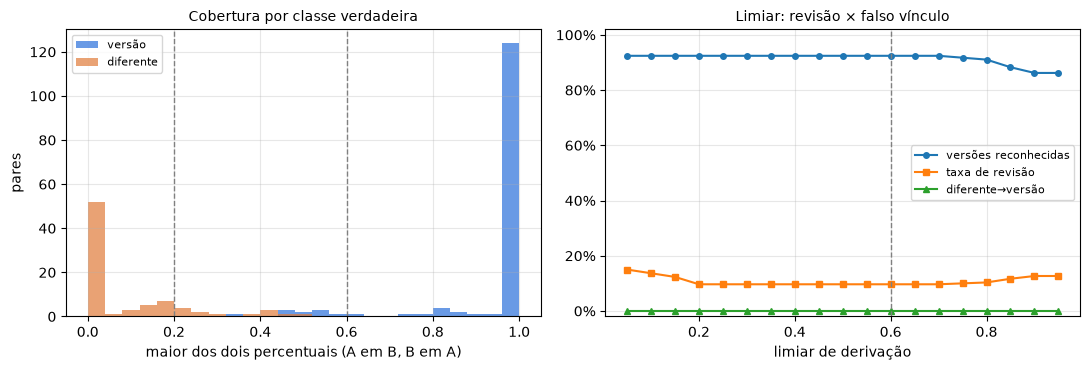

 limiar  versões reconhecidas  taxa de revisão  diferente→versão
   0.10                 92.4%            13.7%              0.0%
   0.20                 92.4%             9.7%              0.0%
   0.30                 92.4%             9.7%              0.0%
   0.40                 92.4%             9.7%              0.0%
   0.50                 92.4%             9.7%              0.0%
   0.60                 92.4%             9.7%              0.0%
   0.70                 92.4%             9.7%              0.0%
   0.80                 91.0%            10.3%              0.0%
   0.90                 86.2%            12.7%              0.0%


In [30]:
grade = [round(x, 2) for x in np.arange(0.05, 0.96, 0.05)]
curva = []
for t in grade:
    lim = replace(LIMIARES, derivacao=t, diferente=min(LIMIARES.diferente, t))
    prev = [previsto_sistema(l, lim) for l in calibracao]
    versoes = [p for l, p in zip(calibracao, prev) if l["verdade"] == "versão"]
    curva.append({
        "limiar": t,
        "versões reconhecidas": sum(p == "versão" for p in versoes) / len(versoes),
        "taxa de revisão": sum(p == "revisão necessária" for p in prev) / len(prev),
        "diferente→versão": sum(p == "versão" for l, p in zip(calibracao, prev) if l["verdade"] == "diferente") / sum(l["verdade"] == "diferente" for l in calibracao),
        "falso cópia": sum(p in ("cópia", "cópia com ressalva") and l["verdade"] in ("versão", "diferente") for l, p in zip(calibracao, prev)),
    })
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
comparaveis = [l for l in calibracao if l["evidencia"].extracao_ok and not l["evidencia"].so_cosmetico and not l["evidencia"].texto_igual]
for v, cor in [("versão", "#2a6fdb"), ("diferente", "#e07b39")]:
    ax1.hist([l["evidencia"].pct_alto for l in comparaveis if l["verdade"] == v], bins=np.linspace(0, 1, 26), alpha=0.7, label=v, color=cor)
for limiar in (LIMIARES.diferente, LIMIARES.derivacao):
    ax1.axvline(limiar, color="gray", linestyle="--", linewidth=1)
ax1.set_xlabel("maior dos dois percentuais (A em B, B em A)")
ax1.set_ylabel("pares")
ax1.set_title("Cobertura por classe verdadeira", fontsize=10)
ax1.legend(fontsize=8)
for chave, estilo in [("versões reconhecidas", "-o"), ("taxa de revisão", "-s"), ("diferente→versão", "-^")]:
    ax2.plot(grade, [c[chave] for c in curva], estilo, label=chave, markersize=4)
ax2.axvline(LIMIARES.derivacao, color="gray", linestyle="--", linewidth=1)
ax2.set_xlabel("limiar de derivação")
ax2.set_ylim(-0.02, 1.02)
ax2.yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0))
ax2.legend(fontsize=8, loc="center right")
ax2.set_title("Limiar: revisão × falso vínculo", fontsize=10)
for ax in (ax1, ax2):
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()
print(f"{'limiar':>7}{'versões reconhecidas':>22}{'taxa de revisão':>17}{'diferente→versão':>18}")
for c in curva[1::2]:
    print(f"{c['limiar']:>7.2f}{c['versões reconhecidas']:>22.1%}{c['taxa de revisão']:>17.1%}{c['diferente→versão']:>18.1%}")
assert all(c["falso cópia"] == 0 for c in curva)

## 11. Custo e latência

*Afirmação:* Máquina e LLM custam pouco; a revisão humana domina o custo.

In [31]:
medicoes, palavras_medidas = {}, {}
for paginas in (2, 20, 100, 300):
    peca = gerar_peca(random.Random(1000 + paginas), "serviços", n_fatos=(paginas * PARAGRAFOS_POR_PAGINA,) * 2)
    texto_a = peca.texto
    texto_b = texto_a.replace(peca.campos["valor"], "R$ 1,00")
    da, db = indexar(representar("a", texto_a)), indexar(representar("b", texto_b))
    palavras_medidas[paginas] = len(db.palavras)
    medicoes[paginas] = {
        "indexar": medir(lambda: indexar(representar("a", texto_a))),
        "comparar": medir(lambda: decidir(comparar(da, db))),
    }
pdf_20 = gerar_pdf(gerar_peca(random.Random(1020), "serviços", n_fatos=(100, 100)).paragrafos, "Cabeçalho")
paginas_pdf_20 = pymupdf.open(stream=pdf_20, filetype="pdf").page_count
extracao_por_pagina = medir(lambda: extrair_pdf(pdf_20)) / paginas_pdf_20
fidelidade_por_pagina = medir(lambda: extracao_confiavel(pdf_20)) / paginas_pdf_20      # já incluída na extração
raster_por_pagina = medir(lambda: rasters_iguais(pdf_20, pdf_20)) / paginas_pdf_20      # par, só quando ia sair cópia com o mesmo layout

print(f"extração de PDF digital: {extracao_por_pagina * 1000:.1f} ms/página, dos quais {fidelidade_por_pagina * 1000:.1f} ms da verificação de fidelidade; "
      f"raster dos dois lados a 72 dpi: {raster_por_pagina * 1000:.1f} ms/página (OCR, quando necessário, custa ordens de grandeza a mais)")
print(f"{'páginas':>8}{'indexar (ms)':>14}{'comparar par (ms)':>19}")
for paginas, m in medicoes.items():
    print(f"{paginas:>8}{m['indexar'] * 1000:>14.1f}{m['comparar'] * 1000:>19.1f}")
por_palavra = medicoes[300]["comparar"] / palavras_medidas[300]
print(f"comparar: {por_palavra * 1e6:.2f} µs por palavra do documento já no caso → limite de força bruta de {LIMITE_PALAVRAS_FORCA_BRUTA:,} palavras "
      f"≈ {LIMITE_PALAVRAS_FORCA_BRUTA * por_palavra:.1f} s de comparação por upload; 200 autos de 300 páginas seriam "
      f"{200 * palavras_medidas[300] * por_palavra:.0f} s, 200 petições de 2 páginas {200 * palavras_medidas[2] * por_palavra:.2f} s")
assert 1 <= LIMITE_PALAVRAS_FORCA_BRUTA * por_palavra <= 4

# Embedding: só os parágrafos próprios não alinhados dos pares na faixa de 20–60%, uma vez por parágrafo (cache).
textos_embedding = [paragrafo_de_fatos(random.Random(9000 + k), "consumo") for k in range(128)]
t0 = time.perf_counter()
EMBEDDINGS.vetores(textos_embedding)
ms_embedding = (time.perf_counter() - t0) / len(textos_embedding) * 1000
print(f"embedding ({MODELO_EMBEDDING.split('/')[-1]}, CPU, lotes de 64): {ms_embedding:.0f} ms por parágrafo, calculado só na faixa e guardado")

extração de PDF digital: 9.3 ms/página, dos quais 3.5 ms da verificação de fidelidade; raster dos dois lados a 72 dpi: 1.2 ms/página (OCR, quando necessário, custa ordens de grandeza a mais)
 páginas  indexar (ms)  comparar par (ms)
       2           2.1                0.7
      20          16.4                5.9
     100          81.8               44.2
     300         248.5              139.6
comparar: 1.26 µs por palavra do documento já no caso → limite de força bruta de 2,000,000 palavras ≈ 2.5 s de comparação por upload; 200 autos de 300 páginas seriam 28 s, 200 petições de 2 páginas 0.24 s


embedding (paraphrase-multilingual-mpnet-base-v2, CPU, lotes de 64): 20 ms por parágrafo, calculado só na faixa e guardado


In [32]:
PREMISSAS = {
    "páginas por documento (mediana)": 20,
    "documentos já no caso (média)": 30,
    "fração de páginas que exigem OCR": 0.10,
    "segundos de OCR por página (latência)": 2.0,
    "US$ por mil páginas de OCR gerenciado": 1.5,   # preço de tabela (Document AI/Textract), conferir na data
    "R$ por US$": 5.4,                              # conferir na data
    "abstenção por par (cenários, hipótese)": (0.002, 0.005, 0.012),
    "fração auditada": 0.01,                        # documentos decididos sem revisão, revistos às cegas
    "minutos por revisão": 5,
    "R$ por hora de revisor": 60.0,
    "R$ por vCPU-hora": 0.25,
    "tokens de entrada por chamada de LLM": payload["tokens_estimados"],
    "tokens de saída por chamada de LLM": 300,
    "R$ por milhão de tokens de entrada": 15.0,
    "R$ por milhão de tokens de saída": 75.0,
}
for k, v in PREMISSAS.items():
    print(f"  {k}: {v}")
custo = lambda volume, p_par: custo_diario(volume, p_par, PREMISSAS, medicoes, extracao_por_pagina)

print("\nMáquina:")
print(f"{'docs/dia':>9}{'vCPU-hora':>11}{'R$ CPU':>9}{'R$ OCR':>10}")
for volume in (1_000, 10_000, 100_000):
    c = custo(volume, 0.0)
    print(f"{volume:>9,}{c['vCPU-hora']:>11.1f}{c['R$ CPU']:>9.2f}{c['R$ OCR']:>10.0f}")

print("\nRevisão por cenário de abstenção por par (hipóteses; 1.000 docs/dia):")
print(f"{'por par':>8}{'docs c/ revisão':>17}{'revisões/dia':>14}{'h revisão':>11}{'R$ revisão':>12}{'R$ LLM':>9}{'R$ OCR':>9}{'R$ CPU':>9}{'auditorias':>12}{'R$ auditoria':>14}")
custos = {}
for p_par in PREMISSAS["abstenção por par (cenários, hipótese)"]:
    c = custos[p_par] = custo(1_000, p_par)
    print(f"{p_par:>8.1%}{taxa_documento(p_par, PREMISSAS):>17.1%}{c['revisões']:>14.0f}{c['horas de revisão']:>11.1f}{c['R$ revisão']:>12.0f}"
          f"{c['R$ LLM']:>9.2f}{c['R$ OCR']:>9.2f}{c['R$ CPU']:>9.2f}{c['auditorias']:>12.1f}{c['R$ auditoria']:>14.0f}")
assert all(c["R$ revisão"] > 10 * (c["R$ CPU"] + c["R$ LLM"] + c["R$ OCR"]) for c in custos.values())

# Auditoria: quantos dias até ~300 cópias auditadas (regra de três para afirmar versão → cópia ≤ 1%). Estimativa: a fração de
# cópias entre as decisões vem dos pares da §10, cuja mistura de classes é sintética.
fracao_copias = sum(d.classe in ("cópia", "cópia com ressalva") for d in decisoes_teste) / len(decisoes_teste)
copias_auditadas_dia = custos[0.002]["auditorias"] * fracao_copias
print(f"\ncópias entre as decisões (§10): {fracao_copias:.0%} → ~{copias_auditadas_dia:.1f} cópias auditadas/dia; "
      f"~300 cópias auditadas em ~{300 / copias_auditadas_dia:.0f} dias")

  páginas por documento (mediana): 20
  documentos já no caso (média): 30
  fração de páginas que exigem OCR: 0.1
  segundos de OCR por página (latência): 2.0
  US$ por mil páginas de OCR gerenciado: 1.5
  R$ por US$: 5.4
  abstenção por par (cenários, hipótese): (0.002, 0.005, 0.012)
  fração auditada: 0.01
  minutos por revisão: 5
  R$ por hora de revisor: 60.0
  R$ por vCPU-hora: 0.25
  tokens de entrada por chamada de LLM: 1122
  tokens de saída por chamada de LLM: 300
  R$ por milhão de tokens de entrada: 15.0
  R$ por milhão de tokens de saída: 75.0

Máquina:
 docs/dia  vCPU-hora   R$ CPU    R$ OCR
    1,000        0.1     0.03        16
   10,000        1.1     0.26       162
  100,000       10.6     2.65      1620

Revisão por cenário de abstenção por par (hipóteses; 1.000 docs/dia):
 por par  docs c/ revisão  revisões/dia  h revisão  R$ revisão   R$ LLM   R$ OCR   R$ CPU  auditorias  R$ auditoria
    0.2%             5.8%            58        4.9         291     2.29    16.20 

In [33]:
rng_lat = random.Random(1200)
latencias = []
for _ in range(2000):
    paginas = min(600, max(1, int(rng_lat.lognormvariate(math.log(20), 0.9))))   # mediana 20 páginas, cauda longa
    ocr = sum(rng_lat.random() < PREMISSAS["fração de páginas que exigem OCR"] for _ in range(paginas)) * PREMISSAS["segundos de OCR por página (latência)"]
    latencias.append(paginas * extracao_por_pagina + ocr + interpolar(medicoes, paginas, "indexar")
                     + PREMISSAS["documentos já no caso (média)"] * interpolar(medicoes, paginas, "comparar"))
latencias.sort()
p50, p95, p99 = (latencias[int(len(latencias) * q)] for q in (0.50, 0.95, 0.99))
print(f"Latência de processamento por documento (sem fila), 2.000 documentos simulados: p50 {p50:.1f}s | p95 {p95:.1f}s | p99 {p99:.1f}s")
pg = PREMISSAS["páginas por documento (mediana)"]
sem_ocr = pg * extracao_por_pagina + interpolar(medicoes, pg, "indexar") + PREMISSAS["documentos já no caso (média)"] * interpolar(medicoes, pg, "comparar")
print(f"Documento mediano ({pg} páginas) sem OCR: {sem_ocr:.2f}s. A cauda vem do OCR e de documentos longos.")

Latência de processamento por documento (sem fila), 2.000 documentos simulados: p50 4.3s | p95 20.4s | p99 36.9s
Documento mediano (20 páginas) sem OCR: 0.38s. A cauda vem do OCR e de documentos longos.


## 12. Painel

*Afirmação:* Cada item do enunciado com a evidência que o sustenta, verificada.

In [34]:
painel = [
    ("1. Representação", "§1, §2, §7", taxas_imagem["novo scan: ruído + brilho"] >= 0.9 and taxas_imagem["falso positivo"] <= 0.05,
     f"hashes, chave cosmética, cabeçalho, imagens/assinatura, fluxo de palavras com parágrafo e página, citações, campos, tipo de peça; "
     f"pHash: {taxas_imagem['novo scan: ruído + brilho']:.0%} dos novos scans de anexos, {taxas_imagem['falso positivo']:.0%} de falso positivo; "
     f"{len(adulterados) - 1} PDFs com texto igual e página diferente nunca saem cópia (§7.3)"),
    ("2. Quase iguais × vocabulário", "§3, §4, §5", not falhas and exemplo_trabalhado.subtipo == "outra instância do modelo",
     f"exemplo do enunciado = {rotulo_publico(exemplo_trabalhado)}; {len(tabela_borda) - len(falhas)}/{len(tabela_borda)} casos de borda; "
     "mesma área → diferente; citação → diferente; memoriais → outra peça do caso; massa: 20/20 independentes → diferente (§5.2)"),
    ("3. Documentos longos", "§6", decisao_longa.classe == "versão" and payload["tokens_estimados"] <= 3000,
     f"{len(paginas_a)} páginas comparadas em {t2 - t1:.2f}s sem LLM; payload ~{payload['tokens_estimados']} tokens vs ~{tokens_documento:,}"),
    ("4. Avaliação", "§10", m_sistema["falso cópia"] == 0 and provavel_copia_ocr == 0 and memoriais_mesma_peca == 0,
     f"{len(teste)} pares: falso cópia {m_sistema['falso cópia']}; versão→cópia ≤{limite_superior(0, m_sistema['n_versoes']):.1%} a 95%; "
     f"versão como 'provável cópia (OCR)' {provavel_copia_ocr}; revisão {m_sistema['revisão']:.1%}; "
     f"cosseno calibrado: {resultados_ablacao['hash + cosseno do documento inteiro']['falso cópia']} falsos 'cópia'"),
    ("5. Depois da classificação", "§9", segunda["economia"] > 0.99,
     f"ações por classe, trecho 'contém', citação, reaproveitamento, cadastro do caso, fila por documento; decisão do revisor presa à evidência; "
     f"OCR concluído recompara; fila reavaliada com o snapshot novo (§9.5); cache: {segunda['economia']:.1%} dos tokens poupados"),
    ("6. Custo, latência, precisão", "§8, §10.4, §11", recall_caso_grande == 1.0,
     f"índices: recall {recall_caso_grande:.0%} comparando {len(caso_grande.pares):,} de {n_pares:,} pares; p95 {p95:.0f}s; revisão humana domina o custo"),
]
largura = max(len(p[0]) for p in painel)
for item, secoes, verificado, evidencia in painel:
    print(f"{'✅' if verificado else '❌'} {item:<{largura}} | {secoes:<14} | {evidencia}")
assert all(verificado for _, _, verificado, _ in painel)

✅ 1. Representação              | §1, §2, §7     | hashes, chave cosmética, cabeçalho, imagens/assinatura, fluxo de palavras com parágrafo e página, citações, campos, tipo de peça; pHash: 93% dos novos scans de anexos, 0% de falso positivo; 3 PDFs com texto igual e página diferente nunca saem cópia (§7.3)
✅ 2. Quase iguais × vocabulário | §3, §4, §5     | exemplo do enunciado = versão · outra instância do modelo; 53/53 casos de borda; mesma área → diferente; citação → diferente; memoriais → outra peça do caso; massa: 20/20 independentes → diferente (§5.2)
✅ 3. Documentos longos          | §6             | 286 páginas comparadas em 0.14s sem LLM; payload ~1122 tokens vs ~152,421
✅ 4. Avaliação                  | §10            | 860 pares: falso cópia 0; versão→cópia ≤0.7% a 95%; versão como 'provável cópia (OCR)' 0; revisão 7.9%; cosseno calibrado: 17 falsos 'cópia'
✅ 5. Depois da classificação    | §9             | ações por classe, trecho 'contém', citação, reaproveitamento, cadastro